# Clustering and PCA

In [1]:
import sys; sys.path.append("..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import adjusted_rand_score, silhouette_samples, silhouette_score

from src import sector_pca as sp
from src import text_clusters as tc
from src.cluster_plots import (plot_dendrogram, plot_heatmap, plot_hier_k_scan, plot_k_sweep,
                               plot_projection_facets, plot_scree, plot_silhouette,
                               plot_silhouette_compare)
from src.plotstyle import CONTROL, EXPOSED, PALETTE, SEQUENTIAL, apply_style, save

apply_style()
pd.set_option("display.max_colwidth", 200)
report = []  # lines for results/clustering_report.txt

## Data preparation

In [2]:
postings, load_log = tc.load_postings()
print("\n".join(load_log))
print(f"unique jobId: {postings.jobId.nunique():,}")
report += ["DATA", *[f"  {line}" for line in load_log]]

rows before dedup: 4294
near-duplicate groups: 357 (933 rows flagged is_near_dup)
group size distribution (copies per group: number of groups):
  2: 242
  3: 66
  4: 24
  5: 15
  6: 3
  7: 2
  8: 1
  9: 2
  10: 1
  12: 1
removed as extra copies: 576
rows after dedup: 3718
is_junk: column not present in ats_final.csv, nothing to drop
unique jobId: 3,718


In [3]:
stripped_text, boiler_summary = tc.strip_boilerplate(postings)
print(f"boilerplate rule: sentence in >= {tc.BOILERPLATE_SHARE:.0%} of a company's postings "
      f"and in >= {tc.BOILERPLATE_MIN} of them; company names removed afterwards")
print(f"median description length: raw {postings.description_clean.str.len().median():,.0f} chars, "
      f"stripped {stripped_text.str.len().median():,.0f} chars")
boiler_summary

boilerplate rule: sentence in >= 10% of a company's postings and in >= 3 of them; company names removed afterwards
median description length: raw 6,329 chars, stripped 3,278 chars


,company,postings,boilerplate_sentences,median_chars_before,median_chars_after,pct_chars_removed
0,Databricks,760,35,5361,3068,39.6
1,OpenAI,750,26,6770,3854,42.4
2,Anthropic,550,53,7995,3822,50.7
3,Scale AI,207,30,6381,3365,46.0
4,Harvey,206,24,5005,3064,37.3
5,Sierra,164,96,7075,2125,66.6
6,Palantir,150,61,7270,3195,51.4
7,Cohere,136,50,6174,2867,51.1
8,Figma,120,47,6365,2464,60.4
9,Ramp,120,53,5747,2777,48.9


In [4]:
TEXTS = {"raw": postings.description_clean, "stripped": stripped_text}
LABEL = {"raw": "raw descriptions", "stripped": "company boilerplate removed"}
roles = postings.role_family  # held out: never passed to any clustering or projection fit

X, terms = {}, {}
for v, text in TEXTS.items():
    X[v], vectorizer = tc.build_tfidf(text)
    terms[v] = vectorizer.get_feature_names_out()
    line = (f"{v}: TF-IDF {X[v].shape[0]:,} x {X[v].shape[1]:,}, vocabulary {len(terms[v]):,}, "
            f"density {X[v].nnz / np.prod(X[v].shape):.2%}")
    print(line)
    report.append(f"  {line}")
print("TF-IDF parameters:", tc.TFIDF_PARAMS)

raw: TF-IDF 3,718 x 7,816, vocabulary 7,816, density 4.62%


stripped: TF-IDF 3,718 x 7,495, vocabulary 7,495, density 2.65%
TF-IDF parameters: {'min_df': 5, 'max_df': 0.8, 'stop_words': 'english'}


## 1. Partitional clustering: k-means

In [5]:
# 14 values of k x 5 seeds x 2 variants; takes a few minutes
SWEEP_KS, SEEDS = range(2, 16), range(5)
sweep = {v: tc.kmeans_sweep(X[v], ks=SWEEP_KS, seeds=SEEDS) for v in X}
for v in sweep:
    print(v)
    display(sweep[v].round(4))
for v in sweep:
    best = sweep[v].silhouette.idxmax()
    print(f"{v}: sweep covers k = {min(SWEEP_KS)} to {max(SWEEP_KS)}; argmax of mean silhouette "
          f"= k {best} ({sweep[v].silhouette.max():.4f}); top of range: {best == max(SWEEP_KS)}")

raw


,inertia,silhouette,silhouette_sd,stability_ari
k,,,,
2,3061.4006,0.0554,0.0000,1.0000
3,2907.9162,0.0768,0.0000,1.0000
4,2771.3368,0.0977,0.0000,1.0000
5,2688.4443,0.1091,0.0005,0.8246
6,2629.1439,0.1211,0.0009,0.8169
7,2565.7618,0.1305,0.0028,0.7683
8,2489.9457,0.1448,0.0007,0.8938
9,2438.6208,0.1497,0.0018,0.8982
10,2371.0978,0.1615,0.0045,0.8861


stripped


,inertia,silhouette,silhouette_sd,stability_ari
k,,,,
2,3333.7157,0.0153,0.0000,0.9987
3,3298.3304,0.0156,0.0000,0.9911
4,3266.8315,0.0102,0.0003,0.8790
5,3239.8303,0.0123,0.0003,0.7474
6,3219.4199,0.0141,0.0003,0.6943
7,3201.3896,0.0157,0.0010,0.6274
8,3183.5954,0.0172,0.0008,0.5888
9,3167.2974,0.0177,0.0014,0.5188
10,3152.6129,0.0198,0.0008,0.6191


raw: sweep covers k = 2 to 15; argmax of mean silhouette = k 14 (0.1732); top of range: False
stripped: sweep covers k = 2 to 15; argmax of mean silhouette = k 15 (0.0268); top of range: True


In [6]:
# raw: k = 14. Mean silhouette over five seeds is highest at k = 14 (0.1732), tied with
#   k = 15 to four decimals (0.17325 against 0.17317). Every k within one seed SD of that
#   top (SD 0.0146 at k = 14) is a candidate: k = 10, 11, 12, 14 and 15. Of these, k = 14
#   is also the most stable across seeds (mean pairwise ARI 0.901, against 0.894 at k = 12,
#   0.886 at k = 10, 0.853 at k = 11 and 0.852 at k = 15). The dip at k = 13 is a poor local
#   optimum rather than structure: inertia rises from 2,285 at k = 12 to 2,292 at k = 13,
#   which a better fit with more clusters would not do. Inertia has no sharp elbow.
# stripped: k = 4. Silhouette sits below 0.03 at every k, so it cannot separate the
#   options; seed stability can. ARI between seeds stays at or above 0.85 up to k = 4
#   (0.88) and falls to 0.75 at k = 5 and 0.69 at k = 6, so k = 4 is the largest k whose
#   clusters are reproducible rather than an artefact of initialisation.
K = {"raw": 14, "stripped": 4}
K_REASON = {
    "raw": "mean silhouette (5 seeds) is highest at k=14 (0.1732, tied with k=15 to 4 dp); "
           "of all k within one seed SD of the top (10, 11, 12, 14, 15), k=14 is the most "
           "stable (ARI 0.901); the k=13 dip is a poor local optimum (inertia rises 2,285 -> 2,292)",
    "stripped": "silhouette < 0.03 at every k so it cannot discriminate; k=4 is the largest "
                "k with seed stability ARI >= 0.85 (0.88; falls to 0.75 at k=5, 0.69 at k=6)",
}
km = {v: tc.fit_kmeans(X[v], K[v]) for v in X}
for v in X:
    print(f"{v}: k = {K[v]}, silhouette of final fit = {silhouette_score(X[v], km[v].labels_):.4f}, "
          f"sizes = {np.bincount(km[v].labels_).tolist()}")
# the sweep's silhouette is a mean over seeds; the final model is the single seed-RANDOM_STATE fit
for v in X:
    row = sweep[v].loc[K[v]]
    print(f"{v} k={K[v]}: seed-averaged silhouette {row.silhouette:.3f} "
          f"(SD {row.silhouette_sd:.4f} over {len(SEEDS)} seeds); chosen-seed run "
          f"(seed {tc.RANDOM_STATE}) {silhouette_score(X[v], km[v].labels_):.3f}")

raw: k = 14, silhouette of final fit = 0.1850, sizes = [545, 297, 147, 120, 120, 205, 164, 751, 748, 48, 135, 207, 131, 100]


stripped: k = 4, silhouette of final fit = 0.0106, sizes = [1111, 493, 1496, 618]


raw k=14: seed-averaged silhouette 0.173 (SD 0.0146 over 5 seeds); chosen-seed run (seed 0) 0.185


stripped k=4: seed-averaged silhouette 0.010 (SD 0.0003 over 5 seeds); chosen-seed run (seed 0) 0.011


In [7]:
# k-means fitted at four k values, which include both chosen k, compared side by side
KS_COMPARE = [3, 4, 8, 14]
compare, compare_labels = {}, {}
for v in X:
    compare[v], compare_labels[v] = tc.kmeans_compare(X[v], KS_COMPARE, postings)
    print(v)
    display(compare[v].round(3))

raw


,silhouette,pct_negative_silhouette,smallest,largest,sizes,nmi_company,nmi_role_family,ari_role_family
k,,,,,,,,
3,0.077,6.105,747,2220,"[2220, 751, 747]",0.550,0.055,0.028
4,0.098,6.267,544,1676,"[1676, 751, 747, 544]",0.675,0.059,0.022
8,0.144,6.267,120,1056,"[1056, 751, 747, 544, 205, 164, 131, 120]",0.835,0.064,0.021
14,0.185,2.905,48,751,"[751, 748, 545, 297, 207, 205, 164, 147, 135, 131, 120, 120, 100, 48]",0.961,0.080,0.024


stripped


,silhouette,pct_negative_silhouette,smallest,largest,sizes,nmi_company,nmi_role_family,ari_role_family
k,,,,,,,,
3,0.016,24.233,920,1606,"[1606, 1192, 920]",0.054,0.272,0.191
4,0.011,34.723,493,1496,"[1496, 1111, 618, 493]",0.060,0.338,0.236
8,0.017,37.466,71,1026,"[1026, 1010, 461, 433, 421, 190, 106, 71]",0.090,0.317,0.225
14,0.025,34.911,16,620,"[620, 554, 493, 431, 405, 304, 261, 222, 147, 128, 70, 39, 28, 16]",0.122,0.347,0.167


### 1a. Raw descriptions

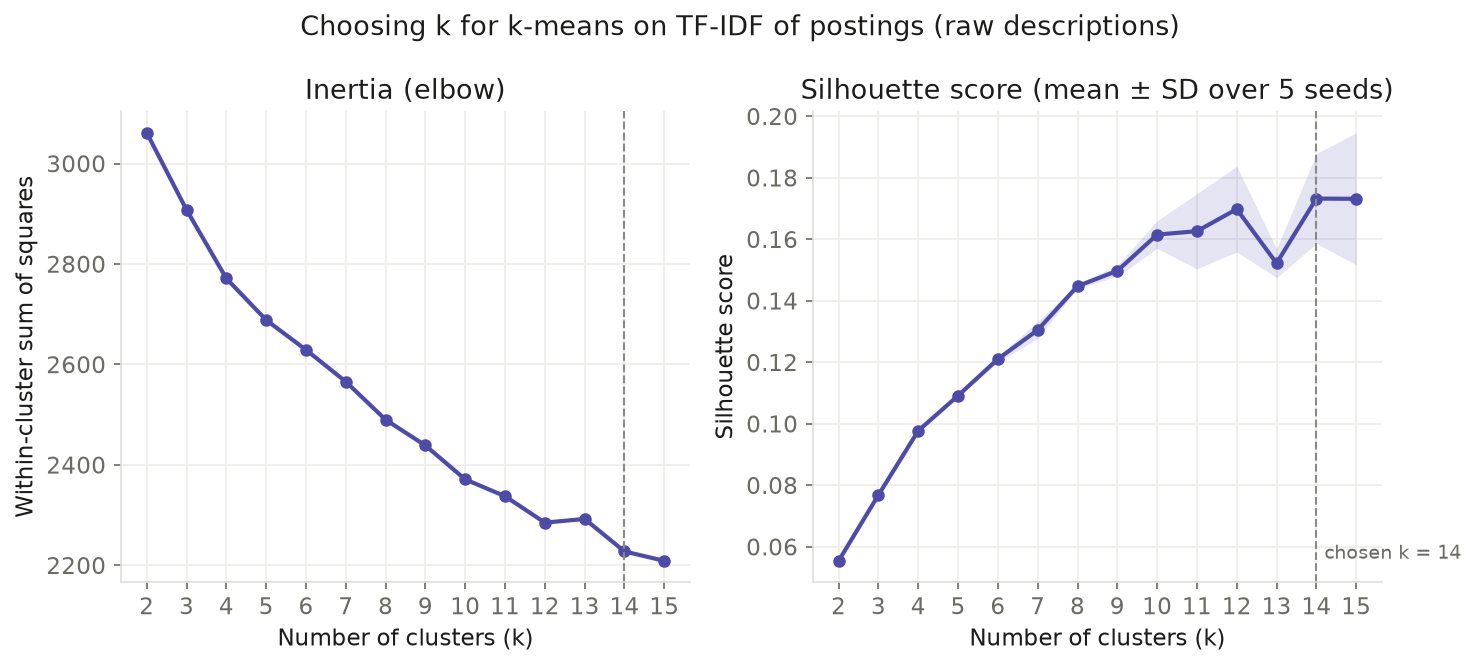

In [8]:
fig = plot_k_sweep(sweep["raw"], K["raw"], LABEL["raw"])
save(fig, "ats_kmeans_k_sweep_raw")

## Insight
Inertia has no clear elbow. The silhouette score is highest at k = 14 and k = 15, which tie at 0.173, and of every k within the seed-to-seed spread of that top, k = 14 is also the most stable across random starts (0.901), so it was chosen. The dip at k = 13 is a poor fit rather than real structure, since inertia rises there (2,285 to 2,292).

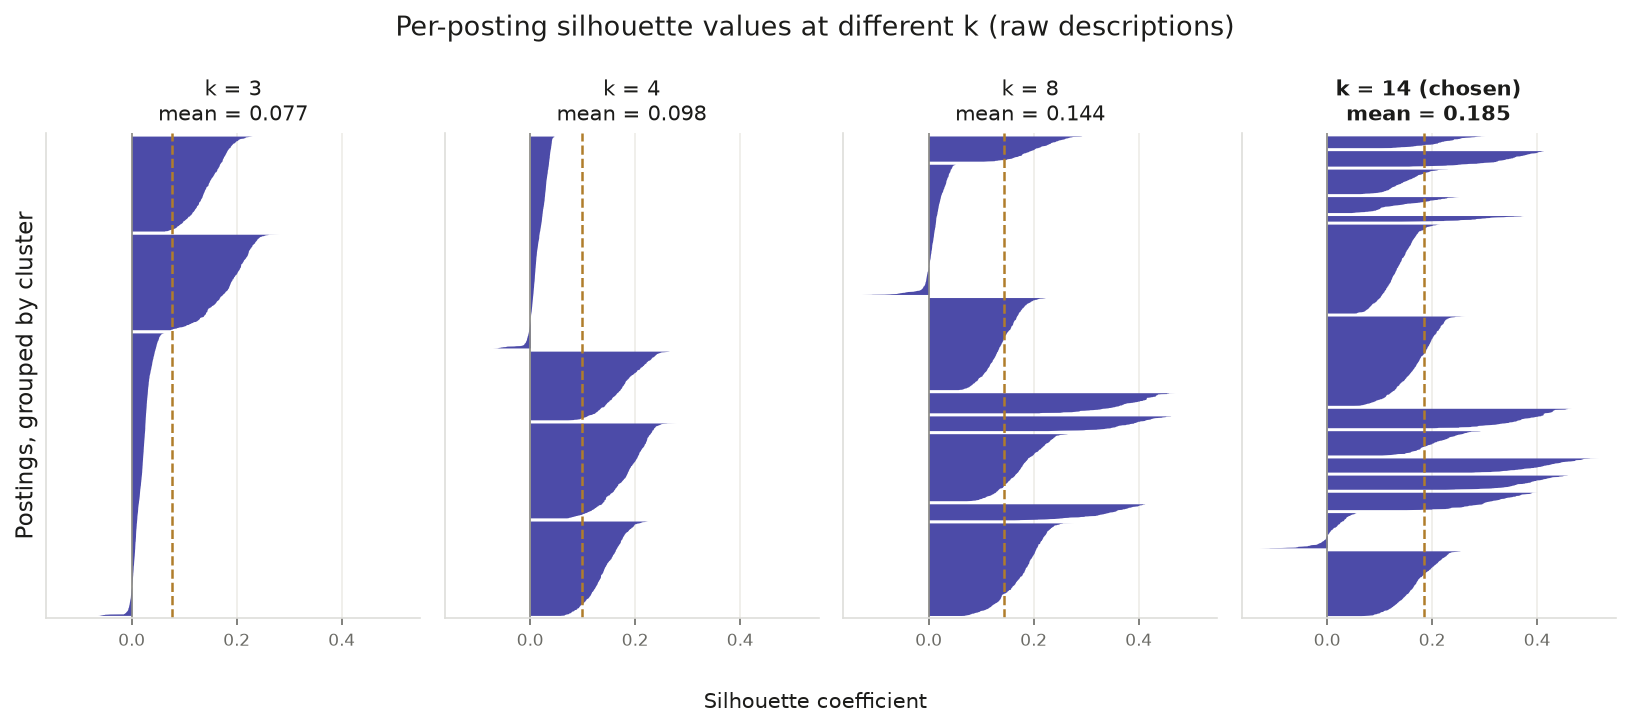

In [9]:
fig = plot_silhouette_compare(X["raw"], compare_labels["raw"], K["raw"], LABEL["raw"])
save(fig, "ats_kmeans_silhouette_compare_raw")

## Insight
The average silhouette rises from 0.077 at k = 3 to 0.185 at k = 14, and the share of postings with negative values falls to 2.9%, so k = 14 is the best of the four.

,mean,pct_negative,n
cluster,,,
K0,0.168,0.000,545
K1,0.007,36.364,297
K2,0.307,0.000,147
K3,0.376,0.000,120
K4,0.410,0.000,120
K5,0.203,0.000,205
K6,0.370,0.000,164
K7,0.168,0.000,751
K8,0.131,0.000,748


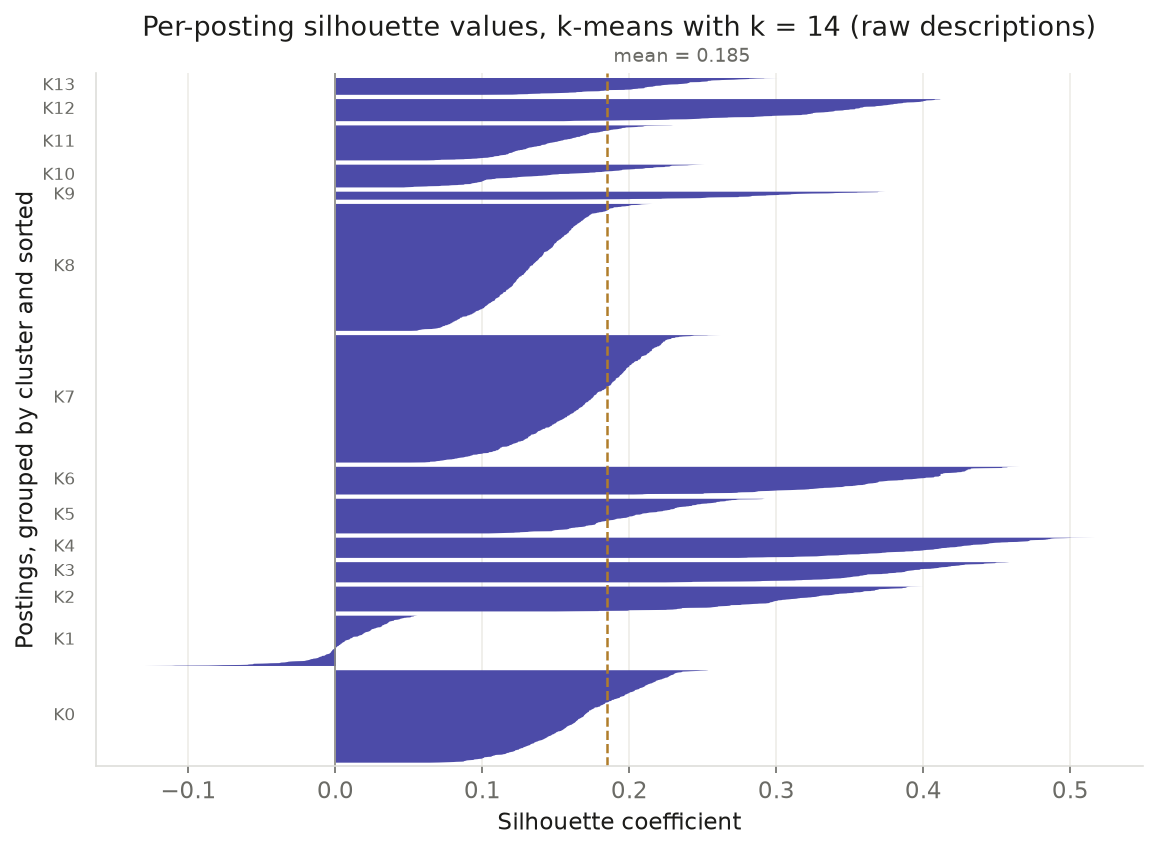

In [10]:
fig = plot_silhouette(X["raw"], km["raw"].labels_, K["raw"], LABEL["raw"])
save(fig, "ats_kmeans_silhouette_raw")

# mean silhouette and share of negative values in each cluster
values = silhouette_samples(X["raw"], km["raw"].labels_)
(pd.DataFrame({"cluster": km["raw"].labels_, "silhouette": values})
 .groupby("cluster").silhouette
 .agg(mean="mean", pct_negative=lambda s: 100 * (s < 0).mean(), n="size")
 .rename(index=lambda c: f"K{c}").round(3))

## Insight
Most postings fit their own cluster well: K1, a mix of smaller companies, is the only cluster with any negative values (36% of its postings, mean 0.01), while small single-company clusters such as Ramp (K4, 0.41) and Figma (K3, 0.38) score highest.

role_family,software_eng,sales_gtm,solutions,forward_deployed,product,applied_ai,research,data,recruiting,other
K9 (n=48),45.8,2.1,0.0,0.0,10.4,0.0,0.0,4.2,0.0,37.5
K10 (n=135),9.6,44.4,1.5,0.0,3.0,0.7,0.0,0.0,2.2,38.5
K5 (n=205),18.0,15.6,1.5,0.0,4.4,0.0,0.5,1.5,2.4,56.1
K8 (n=748),22.1,4.5,2.4,2.3,2.4,4.9,2.4,3.2,0.5,55.2
K4 (n=120),14.2,15.0,6.7,0.8,3.3,1.7,0.0,1.7,3.3,53.3
K0 (n=545),18.5,16.1,1.5,0.4,3.1,4.8,6.4,1.8,1.1,46.2
K13 (n=100),17.0,15.0,6.0,1.0,10.0,0.0,0.0,3.0,2.0,46.0
K11 (n=207),19.8,3.9,2.9,7.2,6.3,3.9,7.2,1.4,1.4,45.9
K1 (n=297),21.2,13.8,6.4,2.0,5.4,2.4,0.3,2.4,1.3,44.8
K12 (n=131),10.7,13.7,8.4,13.7,2.3,1.5,3.1,3.1,1.5,42.0


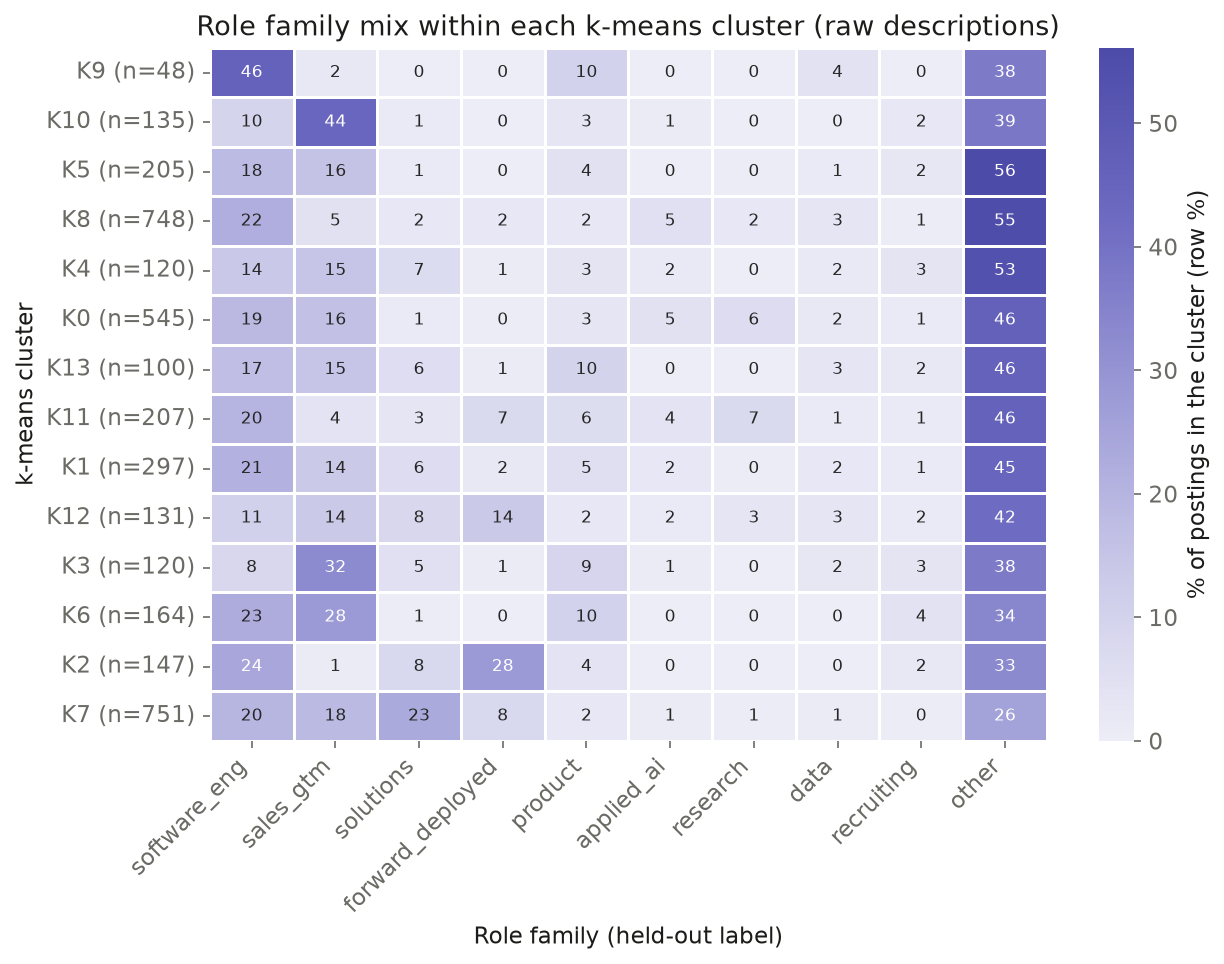

In [11]:
ct = tc.role_crosstab(km["raw"].labels_, roles, prefix="K")
fig = plot_heatmap(ct, f"Role family mix within each k-means cluster ({LABEL['raw']})",
                   "Role family (held-out label)", "k-means cluster",
                   "% of postings in the cluster (row %)", figsize=(9, 6))
save(fig, "ats_kmeans_role_family_raw")

# the heatmap values: role family mix within each cluster (row %)
ct.round(1)

## Insight
No cluster lines up with a role family: "other" is the largest group in 12 of the 14 clusters. Instead, the clusters follow employers, and 12 of them hold postings from a single company, because each company repeats the same boilerplate text in every posting.

In [12]:
sizes = np.bincount(km["raw"].labels_)
for c, words in tc.top_terms(km["raw"].cluster_centers_, terms["raw"]).items():
    print(f"K{c} (n={sizes[c]}): {', '.join(words)}")

K0 (n=545): anthropic, research, single, range, systems, sales, policy, science, beneficial, steerable, visas, sponsor, directions, minimum, visa
K1 (n=297): vercel, amplitude, perplexity, webflow, product, airtable, web, infrastructure, products, technical, systems, marketing, ll, agents, customer
K2 (n=147): palantir, need, life, note, employees, empower, software, palantirians, community, paid, world, lives, accommodation, offerings, year
K3 (n=120): figma, interviews, excited, sales, video, perform, product, design, accommodation, accessible, regardless, candidate, paid, creatives, sick
K4 (n=120): ramp, bonding, weeks, 16, coverage, birthing, 100, pay, medical, insurance, available, reduced, virtual, spend, high
K5 (n=205): harvey, legal, simplicity, professional, product, privacy, services, fast, notices, law, rare, decisiveness, transforming, decades, finished
K6 (n=164): sierra, google, trust, bret, clay, fix, time, values, customers, led, intensity, customer, family, obsession

In [13]:
landing_pct, landing_n = tc.family_landing(km["raw"].labels_, roles, prefix="K")
display(landing_pct)
modal = landing_pct.loc[["forward_deployed", "solutions"]].idxmax(axis=1)
for fam, c in modal.items():
    print(f"{fam}: {landing_n.loc[fam].sum()} postings, modal cluster {c} holds "
          f"{landing_n.loc[fam, c]} ({landing_pct.loc[fam, c]:.1f}%)")
print("forward_deployed and solutions share a modal cluster:", modal.nunique() == 1)

,K0,K1,K2,K3,K4,K5,K6,K7,K8,K9,K10,K11,K12,K13
role_family,,,,,,,,,,,,,,
applied_ai,28.9,7.8,0.0,1.1,2.2,0.0,0.0,6.7,41.1,0.0,1.1,8.9,2.2,0.0
data,15.2,10.6,0.0,4.5,3.0,4.5,0.0,7.6,36.4,3.0,0.0,4.5,6.1,4.5
forward_deployed,1.2,3.7,25.2,0.6,0.6,0.0,0.0,37.4,10.4,0.0,0.0,9.2,11.0,0.6
other,15.9,8.4,3.0,2.8,4.0,7.3,3.5,12.2,26.0,1.1,3.3,6.0,3.5,2.9
product,11.3,10.6,4.0,7.3,2.6,6.0,11.3,11.9,11.9,3.3,2.6,8.6,2.0,6.6
recruiting,12.2,8.2,6.1,8.2,8.2,10.2,14.3,4.1,8.2,0.0,6.1,6.1,4.1,4.1
research,44.9,1.3,0.0,0.0,0.0,1.3,0.0,5.1,23.1,0.0,0.0,19.2,5.1,0.0
sales_gtm,16.3,7.6,0.2,7.2,3.3,5.9,8.5,25.6,6.3,0.2,11.1,1.5,3.3,2.8
software_eng,14.0,8.7,5.0,1.4,2.4,5.1,5.1,20.5,22.9,3.1,1.8,5.7,1.9,2.4


forward_deployed: 163 postings, modal cluster K7 holds 61 (37.4%)
solutions: 275 postings, modal cluster K7 holds 175 (63.6%)
forward_deployed and solutions share a modal cluster: True


In [14]:
print({k: round(val, 3) for k, val in tc.agreement(km["raw"].labels_, postings).items()})
pd.crosstab(pd.Series(km["raw"].labels_, name="k-means cluster"), postings.company_clean)

{'nmi_company': 0.961, 'nmi_role_family': 0.08, 'ari_role_family': 0.024}


company_clean,Airtable,Amplitude,Anthropic,Asana,Cohere,Databricks,Discord,Figma,Harvey,Linear,OpenAI,Palantir,Perplexity,Ramp,Scale AI,Sierra,Stripe,Vercel,Webflow
k-means cluster,,,,,,,,,,,,,,,,,,,
0,0,0,545,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,16,33,5,0,5,9,0,0,1,0,2,3,110,0,0,0,0,85,28
2,0,0,0,0,0,0,0,0,0,0,0,147,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,120,0,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,0,0,0,120,0,0,0,0,0
5,0,0,0,0,0,0,0,0,205,0,0,0,0,0,0,0,0,0,0
6,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,164,0,0,0
7,0,0,0,0,0,751,0,0,0,0,0,0,0,0,0,0,0,0,0
8,0,0,0,0,0,0,0,0,0,0,748,0,0,0,0,0,0,0,0


### 1b. Company boilerplate removed

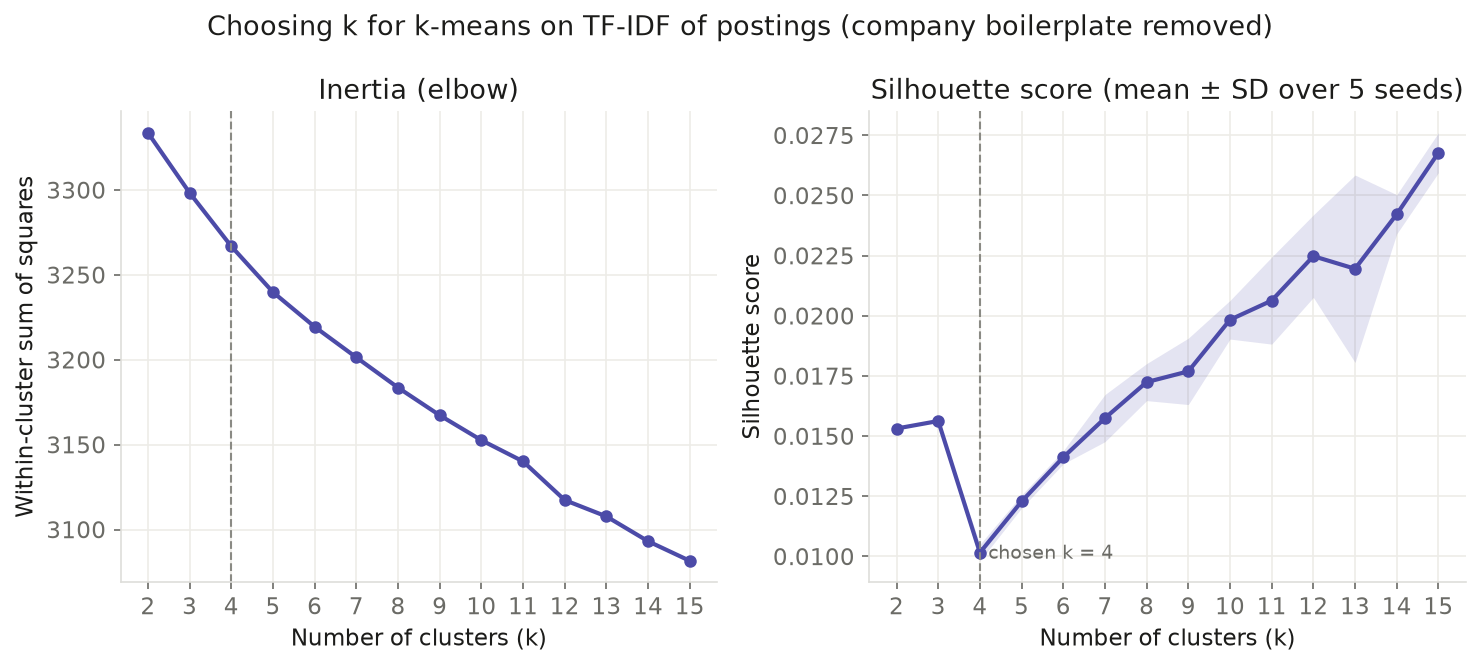

In [15]:
fig = plot_k_sweep(sweep["stripped"], K["stripped"], LABEL["stripped"])
save(fig, "ats_kmeans_k_sweep_stripped")

## Insight
Silhouette is below 0.03 at every k, so it cannot pick a k; k = 4 was chosen as the largest k whose clusters stay the same across random starts (agreement 0.88, falling to 0.75 at k = 5).

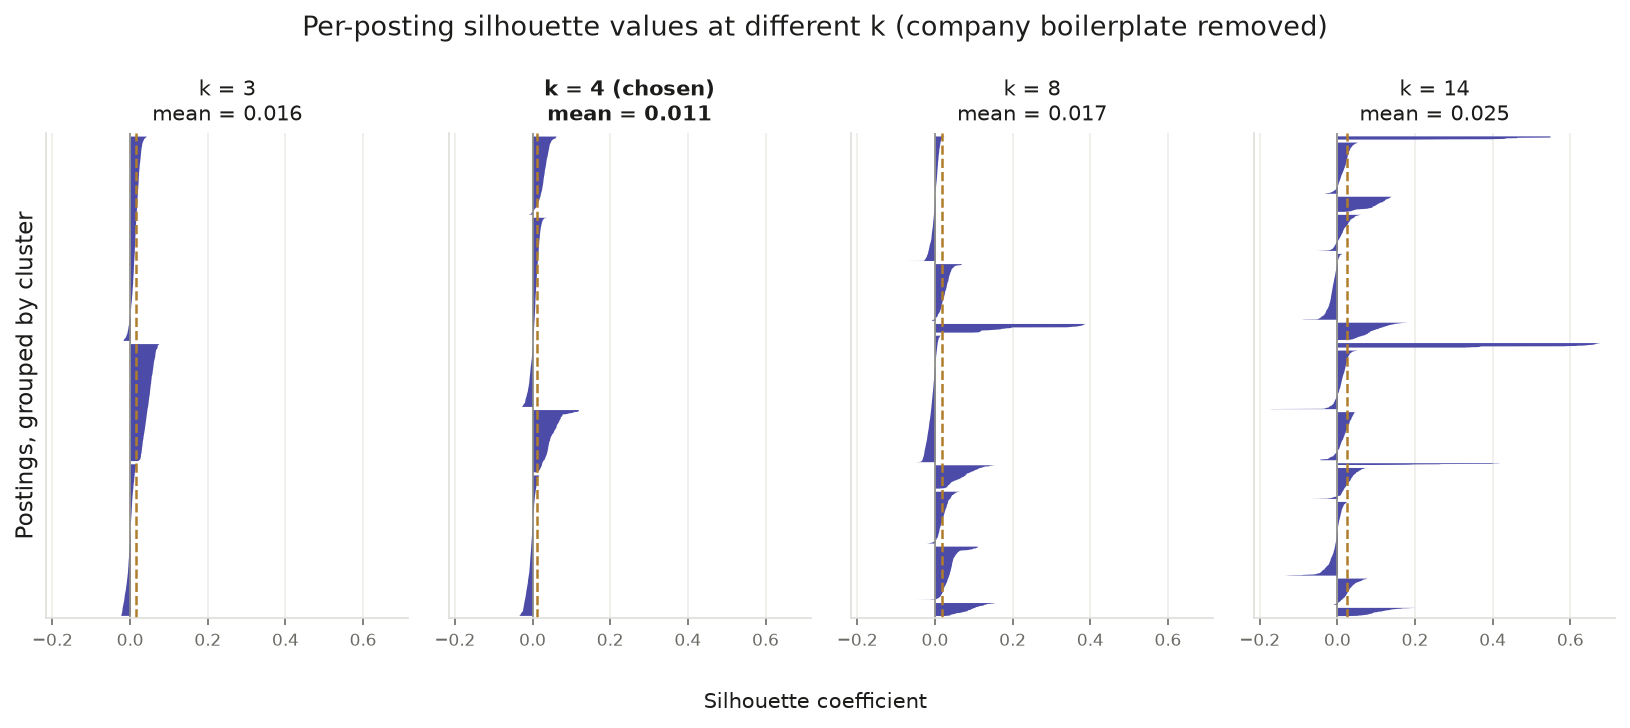

In [16]:
fig = plot_silhouette_compare(X["stripped"], compare_labels["stripped"], K["stripped"], LABEL["stripped"])
save(fig, "ats_kmeans_silhouette_compare_stripped")

## Insight
Across the four k values compared, the average silhouette stays between 0.011 and 0.025, and 24% to 37% of postings have negative values, so none of them gives well-separated groups.

,mean,pct_negative,n
cluster,,,
K0,-0.006,68.587,1111
K1,0.048,0.000,493
K2,0.003,33.690,1496
K3,0.028,4.045,618


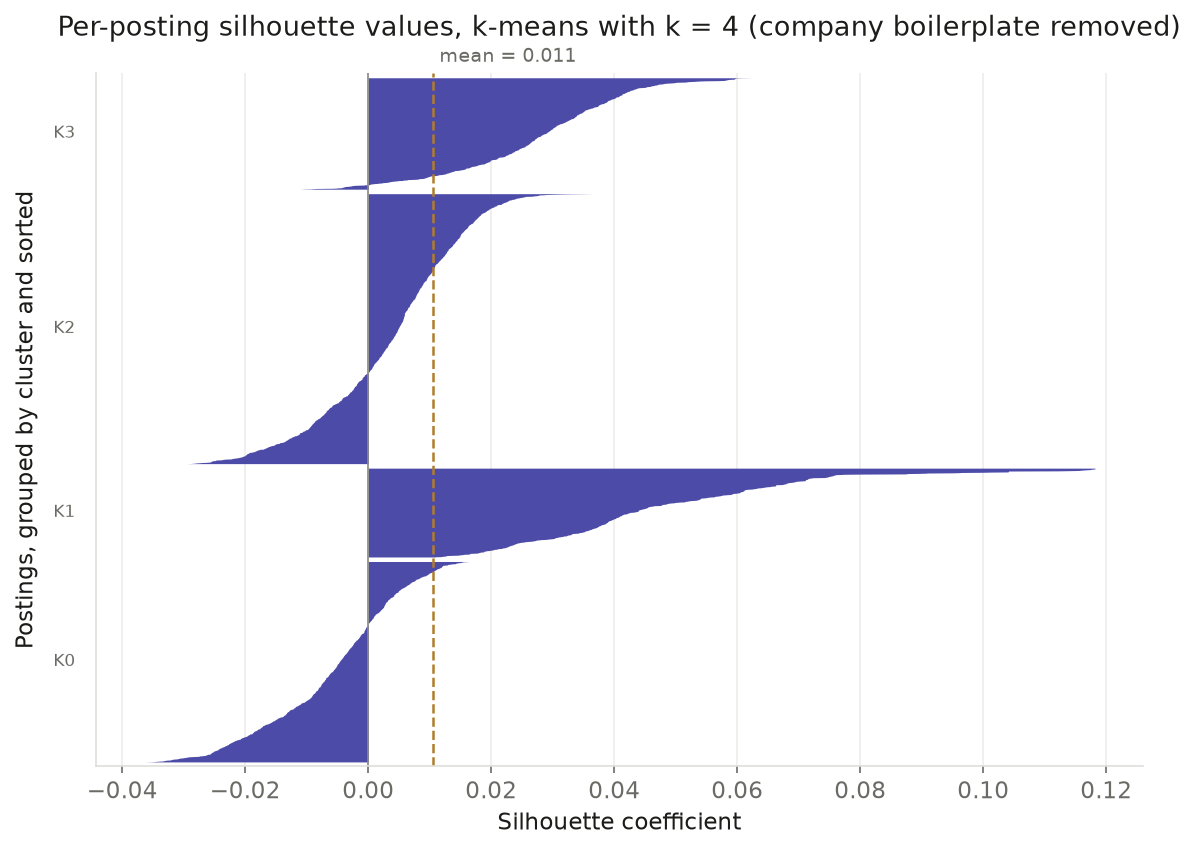

In [17]:
fig = plot_silhouette(X["stripped"], km["stripped"].labels_, K["stripped"], LABEL["stripped"])
save(fig, "ats_kmeans_silhouette_stripped")

# mean silhouette and share of negative values in each cluster
values = silhouette_samples(X["stripped"], km["stripped"].labels_)
(pd.DataFrame({"cluster": km["stripped"].labels_, "silhouette": values})
 .groupby("cluster").silhouette
 .agg(mean="mean", pct_negative=lambda s: 100 * (s < 0).mean(), n="size")
 .rename(index=lambda c: f"K{c}").round(3))

## Insight
The customer-technical (K1) and sales (K3) clusters hold together, while engineering (K2) and the legal and finance cluster (K0) are weak, with 34% and 69% of their postings negative.

role_family,software_eng,sales_gtm,solutions,forward_deployed,product,applied_ai,research,data,recruiting,other
K2 (n=1496),45.1,0.5,1.3,4.6,8.4,3.0,5.1,3.3,0.0,28.8
K3 (n=618),0.0,67.8,1.3,0.5,0.0,0.8,0.0,0.3,0.0,29.3
K1 (n=493),0.0,3.0,43.4,17.0,2.2,7.9,0.0,0.2,0.0,26.2
K0 (n=1111),4.1,8.8,3.1,0.6,1.4,0.1,0.2,1.3,4.4,76.1


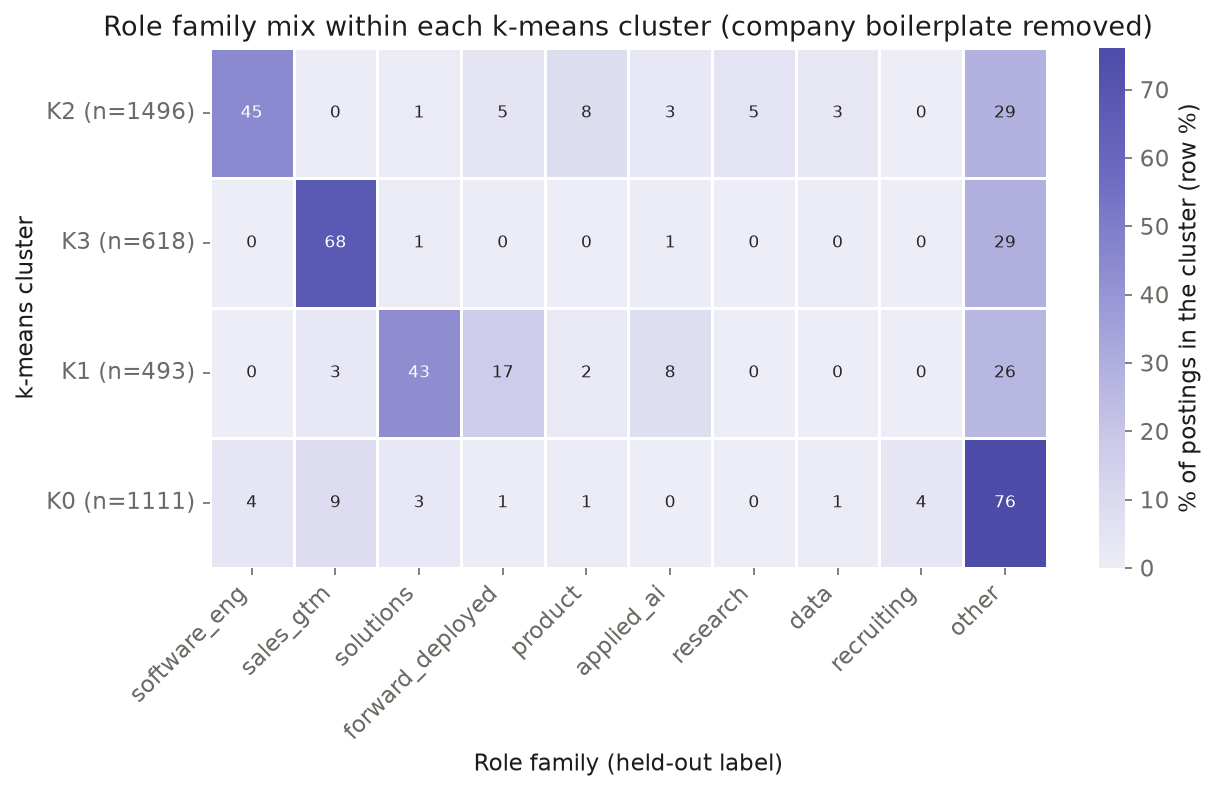

In [18]:
ct = tc.role_crosstab(km["stripped"].labels_, roles, prefix="K")
fig = plot_heatmap(ct, f"Role family mix within each k-means cluster ({LABEL['stripped']})",
                   "Role family (held-out label)", "k-means cluster",
                   "% of postings in the cluster (row %)", figsize=(9, 4.5))
save(fig, "ats_kmeans_role_family_stripped")

# the heatmap values: role family mix within each cluster (row %)
ct.round(1)

## Insight
With boilerplate removed, the clusters follow job types: K3 is 68% sales, K2 is 45% software engineering, and K1 is mainly solutions (43%) and forward_deployed (17%) postings.

In [19]:
sizes = np.bincount(km["stripped"].labels_)
for c, words in tc.top_terms(km["stripped"].cluster_centers_, terms["stripped"]).items():
    print(f"K{c} (n={sizes[c]}): {', '.join(words)}")

K0 (n=1111): legal, ai, product, partner, operations, support, accounting, data, business, work, finance, technical, marketing, program, including
K1 (n=493): customer, technical, customers, data, solutions, engineering, product, ai, sales, account, architecture, adoption, success, delivery, platform
K2 (n=1496): systems, data, infrastructure, ai, product, security, engineering, design, research, work, technical, software, platform, scale, engineers
K3 (n=618): sales, enterprise, account, business, customer, accounts, revenue, market, customers, value, selling, marketing, ai, strategic, product


In [20]:
landing_pct, landing_n = tc.family_landing(km["stripped"].labels_, roles, prefix="K")
display(landing_pct)
modal = landing_pct.loc[["forward_deployed", "solutions"]].idxmax(axis=1)
for fam, c in modal.items():
    print(f"{fam}: {landing_n.loc[fam].sum()} postings, modal cluster {c} holds "
          f"{landing_n.loc[fam, c]} ({landing_pct.loc[fam, c]:.1f}%)")
print("forward_deployed and solutions share a modal cluster:", modal.nunique() == 1)

,K0,K1,K2,K3
role_family,,,,
applied_ai,1.1,43.3,50.0,5.6
data,21.2,1.5,74.2,3.0
forward_deployed,4.3,51.5,42.3,1.8
other,53.3,8.1,27.2,11.4
product,9.9,7.3,82.8,0.0
recruiting,100.0,0.0,0.0,0.0
research,2.6,0.0,97.4,0.0
sales_gtm,18.2,2.8,1.3,77.7
software_eng,6.4,0.0,93.6,0.0


forward_deployed: 163 postings, modal cluster K1 holds 84 (51.5%)
solutions: 275 postings, modal cluster K1 holds 214 (77.8%)
forward_deployed and solutions share a modal cluster: True


In [21]:
print({k: round(val, 3) for k, val in tc.agreement(km["stripped"].labels_, postings).items()})
pd.crosstab(pd.Series(km["stripped"].labels_, name="k-means cluster"), postings.company_clean)

{'nmi_company': 0.06, 'nmi_role_family': 0.338, 'ari_role_family': 0.236}


company_clean,Airtable,Amplitude,Anthropic,Asana,Cohere,Databricks,Discord,Figma,Harvey,Linear,OpenAI,Palantir,Perplexity,Ramp,Scale AI,Sierra,Stripe,Vercel,Webflow
k-means cluster,,,,,,,,,,,,,,,,,,,
0,8,6,254,24,35,93,13,32,95,10,246,38,35,48,72,40,32,26,4
1,0,6,28,11,8,256,0,13,17,5,84,1,2,17,20,15,0,8,2
2,5,17,200,44,70,239,34,33,61,7,339,110,61,31,107,72,19,34,13
3,3,4,68,21,23,172,1,42,33,1,81,1,12,24,8,37,61,17,9


## 2. Hierarchical clustering: cosine distance

In [22]:
# Distance is cosine distance (1 - cosine similarity) and the linkage is COMPLETE.
# Ward is not used because it is defined only for Euclidean distance. Average linkage
# was also fitted (printed below) and rejected: on these distances it chains, so at the
# k-means k it piles most postings into one or two clusters and leaves the rest in small
# groups (stripped: 3,704 of 3,718 in one cluster; raw: 2,943 in two). Complete
# linkage merges two groups by their least similar pair of postings, so a group cannot
# grow by chaining through one close neighbour, and it gives compact clusters of
# comparable size. The cost is a lower cophenetic correlation than average linkage.
#
# The dendrogram is truncated rather than sampled. The cut, the cross-tab and the
# cophenetic correlation all come from this one full tree; a truncated view (the last
# 30 merges) draws that same tree, whereas a sample would draw a different tree from
# the one being evaluated. 3,718 leaves cannot be labelled legibly; 30 can.
P = 30
dist, hier, hier_labels, coph, avg_check = {}, {}, {}, {}, {}
for v in X:
    dist[v] = tc.cosine_distances(X[v])
    hier[v] = tc.cosine_linkage(dist[v], "complete")
    hier_labels[v] = tc.cut_k(hier[v], K[v])
    coph[v] = tc.cophenetic_corr(hier[v], dist[v])
    avg = tc.cosine_linkage(dist[v], "average")
    avg_check[v] = (sorted(np.bincount(tc.cut_k(avg, K[v])).tolist(), reverse=True),
                    tc.cophenetic_corr(avg, dist[v]))
    print(f"{v}, cut at k = {K[v]}")
    print(f"  complete: sizes {sorted(np.bincount(hier_labels[v]).tolist(), reverse=True)}, "
          f"cophenetic correlation {coph[v]:.4f}")
    print(f"  average:  sizes {avg_check[v][0]}, cophenetic correlation {avg_check[v][1]:.4f}")

raw, cut at k = 14
  complete: sizes [902, 716, 694, 571, 270, 222, 92, 66, 49, 48, 41, 20, 18, 9], cophenetic correlation 0.8537
  average:  sizes [1595, 1348, 210, 134, 120, 108, 68, 48, 33, 23, 15, 9, 6, 1], cophenetic correlation 0.9269


stripped, cut at k = 4
  complete: sizes [1892, 1809, 11, 6], cophenetic correlation 0.5445
  average:  sizes [3704, 9, 3, 2], cophenetic correlation 0.6748


In [23]:
# Which k the tree suggests, read two ways over k = 2..15: the largest gap in merge
# height above a cut (the dendrogram reading), and the highest cosine silhouette of a
# cut. The k-means silhouette uses Euclidean distance on L2-normalised rows, which is
# sqrt(2 x cosine distance), so it orders every pair of postings the same way.
scan = {v: tc.hier_k_scan(hier[v], dist[v]) for v in X}
for v in X:
    print(v)
    display(scan[v].round(4))
k_suggest = pd.DataFrame({v: {
    "hierarchical: largest merge gap": scan[v].merge_gap.idxmax(),
    "hierarchical: best cut silhouette": scan[v].silhouette_cosine.idxmax(),
    "k-means: best mean silhouette": sweep[v].silhouette.idxmax(),
    "k-means: chosen k": K[v]} for v in X})
k_suggest

raw


,merge_gap,silhouette_cosine,largest_cluster
k,,,
2,0.0013,0.0960,3709
3,0.0021,0.0573,3581
4,0.0002,0.0887,2595
5,0.0036,0.0834,2595
6,0.0026,0.0679,2595
7,0.0002,0.0932,1662
8,0.0021,0.1214,1662
9,0.0013,0.1299,1662
10,0.0003,0.1281,1596


stripped


,merge_gap,silhouette_cosine,largest_cluster
k,,,
2,0.0000,0.0233,1909
3,0.0000,0.0243,1892
4,0.0000,0.0248,1892
5,0.0008,0.0237,1892
6,0.0011,0.0222,1838
7,0.0006,0.0248,1838
8,0.0010,0.0215,1838
9,0.0004,0.0236,1838
10,0.0005,0.0195,1264


,raw,stripped
hierarchical: largest merge gap,5,6
hierarchical: best cut silhouette,14,7
k-means: best mean silhouette,14,15
k-means: chosen k,14,4


### 2a. Raw descriptions

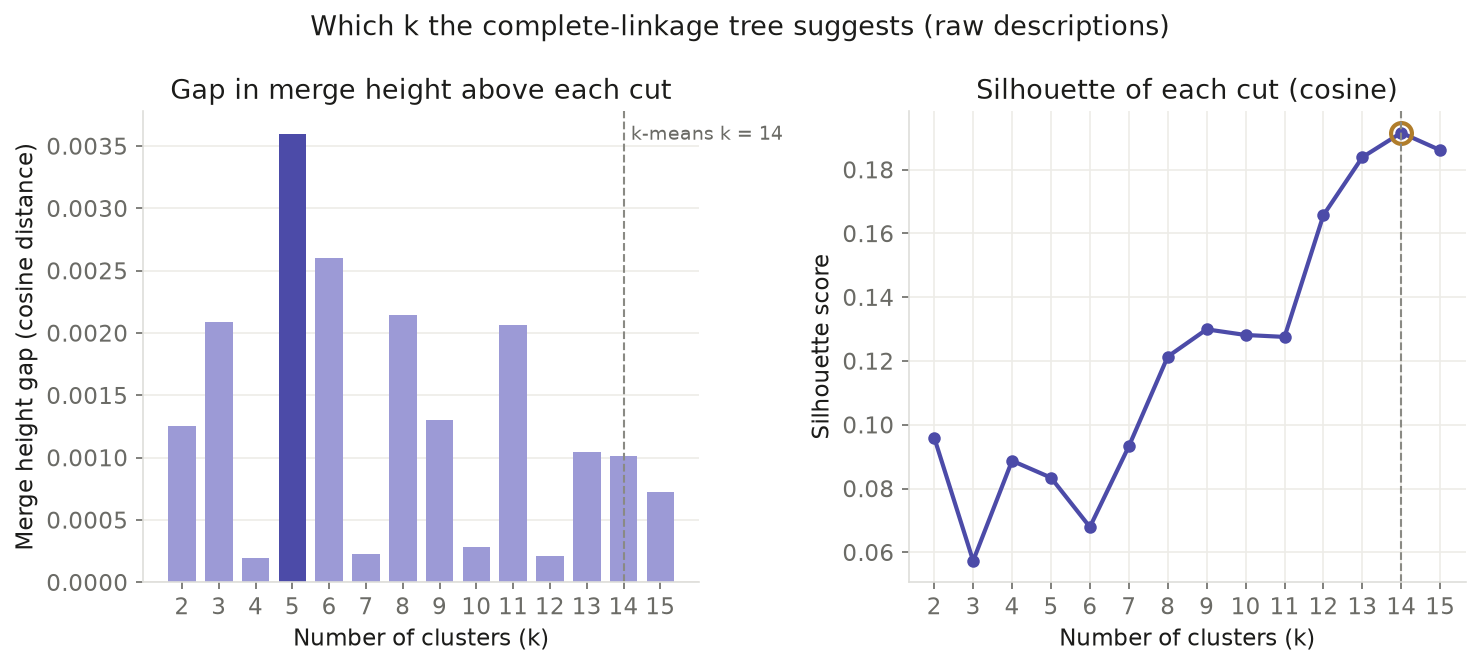

In [24]:
fig = plot_hier_k_scan(scan["raw"], K["raw"], LABEL["raw"])
save(fig, "ats_hier_k_scan_raw")

## Insight
The merge gaps are all tiny, so the dendrogram itself does not point to one k, but the cut silhouette is highest at k = 14 (0.192), the same k chosen for k-means.

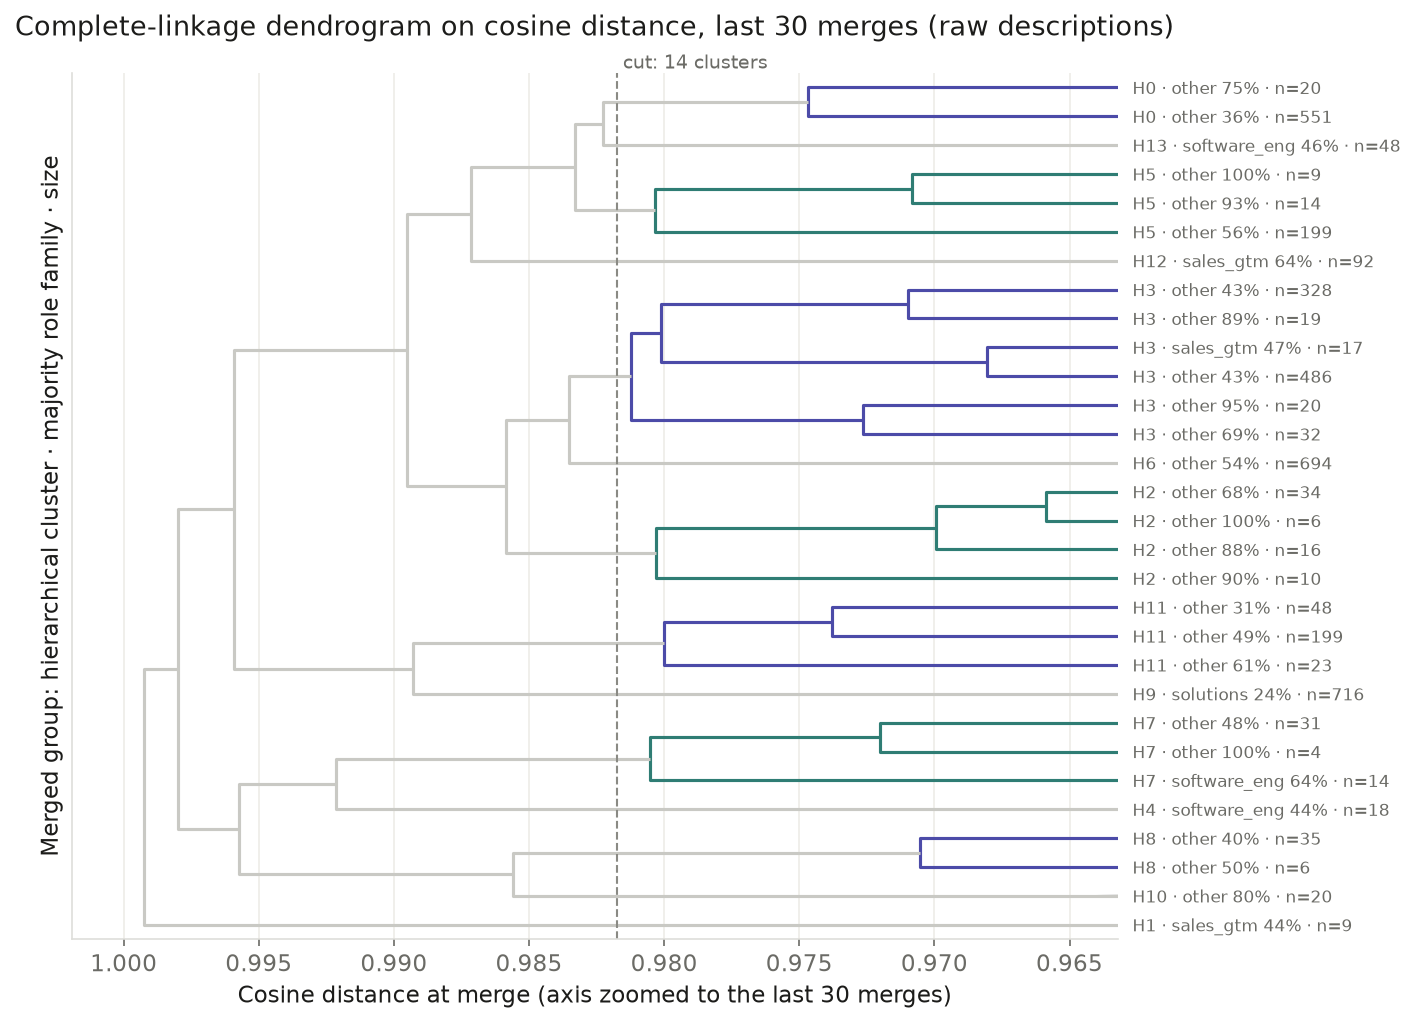

In [25]:
leaf_labels = tc.truncated_leaf_labels(hier["raw"], P, roles, hier_labels["raw"])
fig = plot_dendrogram(hier["raw"], tc.cut_height(hier["raw"], K["raw"]), leaf_labels, P,
                      K["raw"], LABEL["raw"])
save(fig, "ats_hier_dendrogram_raw")

## Insight
The branches follow companies rather than jobs; for example, H9 is 716 Databricks postings and H6 is 694 OpenAI postings. The cophenetic correlation of 0.85 means the tree keeps the original distances well; average linkage scores higher (0.93) but was not used, because it puts 2,943 of the 3,718 postings into just two clusters.

ARI between hierarchical and k-means clusters: 0.696


,K6,K3,K2,K0,K13,K5,K8,K11,K1,K7,K12,K4,K10,K9
H0,164,120,144,3,97,0,0,3,33,5,0,0,2,0
H1,0,0,0,0,0,0,0,0,8,1,0,0,0,0
H2,0,0,3,22,0,2,10,1,14,7,2,0,5,0
H3,0,0,0,517,1,1,33,199,9,8,129,0,5,0
H4,0,0,0,1,1,0,0,0,6,10,0,0,0,0
H5,0,0,0,2,1,199,8,1,9,1,0,0,1,0
H6,0,0,0,0,0,0,694,0,0,0,0,0,0,0
H7,0,0,0,0,0,2,3,2,37,2,0,0,3,0
H8,0,0,0,0,0,0,0,1,40,0,0,0,0,0
H9,0,0,0,0,0,0,0,0,0,716,0,0,0,0


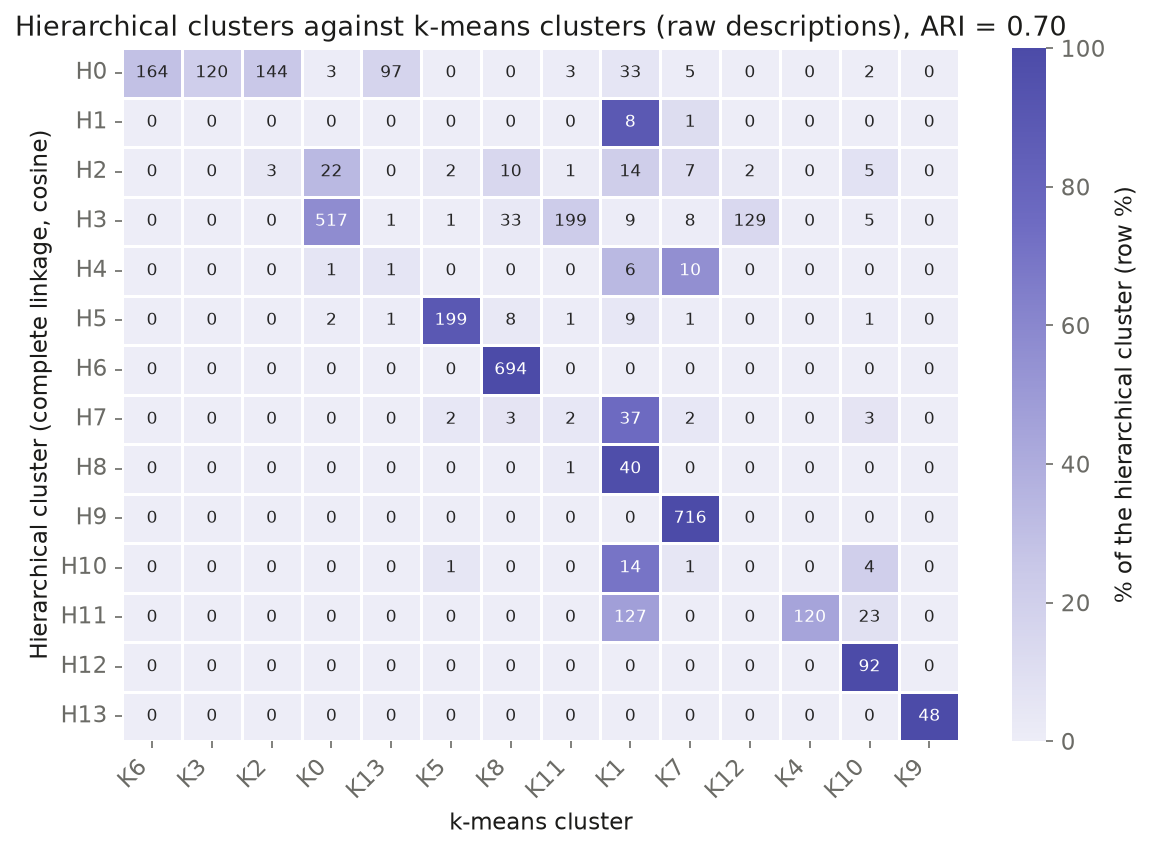

In [26]:
ct = tc.aligned_crosstab(hier_labels["raw"], km["raw"].labels_)
ari = adjusted_rand_score(hier_labels["raw"], km["raw"].labels_)
fig = plot_heatmap(ct, f"Hierarchical clusters against k-means clusters ({LABEL['raw']}), ARI = {ari:.2f}",
                   "k-means cluster", "Hierarchical cluster (complete linkage, cosine)",
                   "% of the hierarchical cluster (row %)",
                   fmt="d", figsize=(9, 6),
                   color_by=ct.div(ct.sum(axis=1), axis=0) * 100)
save(fig, "ats_hier_vs_kmeans_raw")

print(f"ARI between hierarchical and k-means clusters: {ari:.3f}")
ct

## Insight
The two methods agree fairly well (ARI = 0.70). Two large hierarchical clusters sit entirely inside one k-means cluster each: H6 (694 postings) inside the OpenAI cluster K8, and H9 (716) inside the Databricks cluster K7. Others are merged, with H3 combining Anthropic (517), Scale AI (199) and Cohere (134).

In [27]:
print({k: round(val, 3) for k, val in tc.agreement(hier_labels["raw"], postings).items()})
tc.role_crosstab(hier_labels["raw"], roles, prefix="H").round(1)

{'nmi_company': 0.773, 'nmi_role_family': 0.083, 'ari_role_family': 0.018}


role_family,software_eng,sales_gtm,solutions,forward_deployed,product,applied_ai,research,data,recruiting,other
H13 (n=48),45.8,2.1,0.0,0.0,10.4,0.0,0.0,4.2,0.0,37.5
H4 (n=18),44.4,0.0,0.0,0.0,0.0,22.2,5.6,5.6,0.0,22.2
H12 (n=92),14.1,64.1,0.0,0.0,0.0,1.1,0.0,0.0,1.1,19.6
H1 (n=9),11.1,44.4,11.1,22.2,0.0,0.0,0.0,0.0,0.0,11.1
H9 (n=716),19.3,19.1,24.3,8.5,2.5,0.7,0.6,0.7,0.3,24.0
H10 (n=20),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,20.0,80.0
H2 (n=66),9.1,1.5,10.6,0.0,0.0,0.0,0.0,0.0,0.0,78.8
H5 (n=222),15.8,14.4,1.4,0.0,4.1,0.0,0.5,1.8,2.3,59.9
H6 (n=694),22.8,4.6,1.9,2.4,2.6,5.3,2.6,3.3,0.6,53.9
H7 (n=49),40.8,0.0,0.0,2.0,0.0,4.1,0.0,4.1,0.0,49.0


In [28]:
# hierarchical cluster x company
pd.crosstab(pd.Series(hier_labels["raw"], name="hierarchical cluster"),
            postings.company_clean).rename(index=lambda c: f"H{c}")

company_clean,Airtable,Amplitude,Anthropic,Asana,Cohere,Databricks,Discord,Figma,Harvey,Linear,OpenAI,Palantir,Perplexity,Ramp,Scale AI,Sierra,Stripe,Vercel,Webflow
hierarchical cluster,,,,,,,,,,,,,,,,,,,
H0,0,0,3,97,0,5,0,120,0,0,0,144,5,0,3,164,2,0,28
H1,0,0,5,0,0,1,0,0,0,0,0,3,0,0,0,0,0,0,0
H2,1,0,22,0,2,14,0,0,3,0,12,3,0,0,1,0,5,3,0
H3,0,0,517,1,134,10,0,0,1,0,33,0,1,0,199,0,5,1,0
H4,0,0,1,1,0,10,0,0,0,0,0,0,6,0,0,0,0,0,0
H5,0,0,2,1,0,1,0,0,199,0,8,0,7,0,1,0,1,2,0
H6,0,0,0,0,0,0,0,0,0,0,694,0,0,0,0,0,0,0,0
H7,0,0,0,0,0,2,0,0,2,0,3,0,37,0,2,0,3,0,0
H8,0,0,0,0,0,0,0,0,0,0,0,0,40,0,1,0,0,0,0


### 2b. Company boilerplate removed

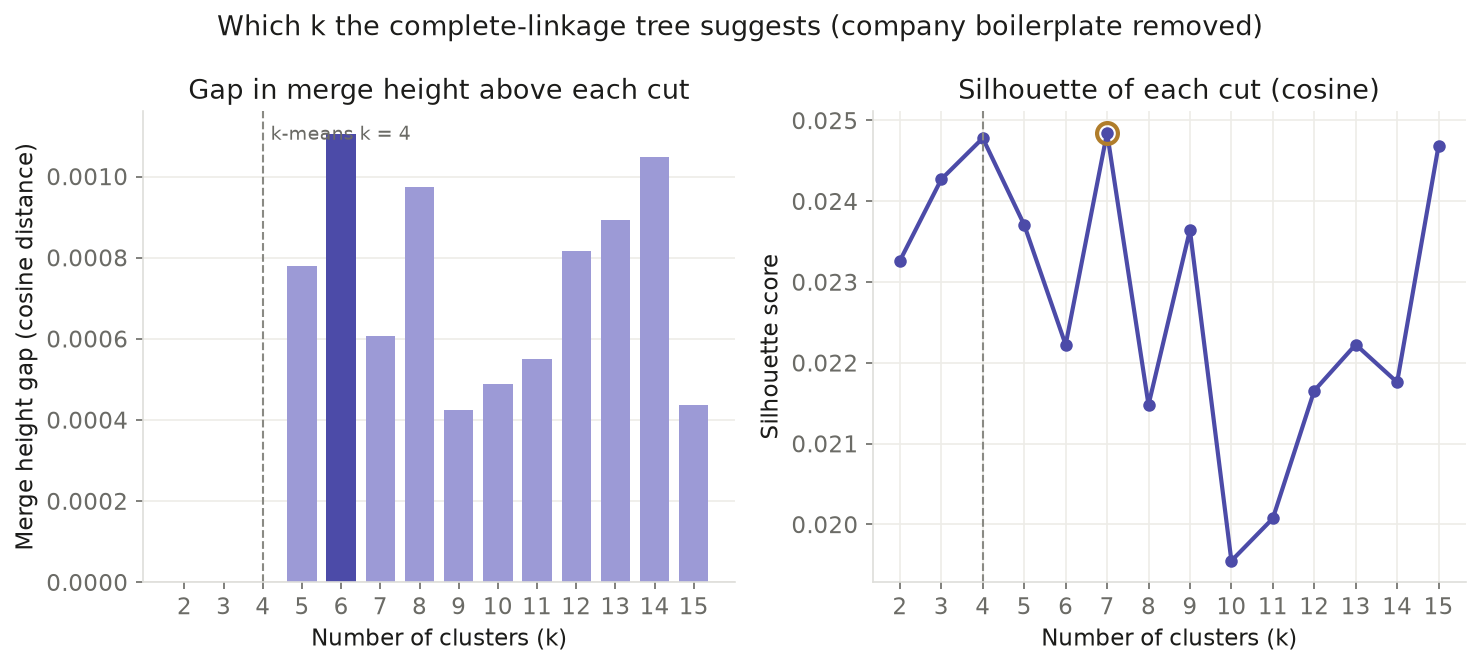

In [29]:
fig = plot_hier_k_scan(scan["stripped"], K["stripped"], LABEL["stripped"])
save(fig, "ats_hier_k_scan_stripped")

## Insight
The cut silhouette is almost flat, with its highest value at k = 7 and an equal value at k = 4 (both 0.025), which matches the k chosen for k-means; the k-means silhouette is instead highest at k = 15, the top of the range tested.

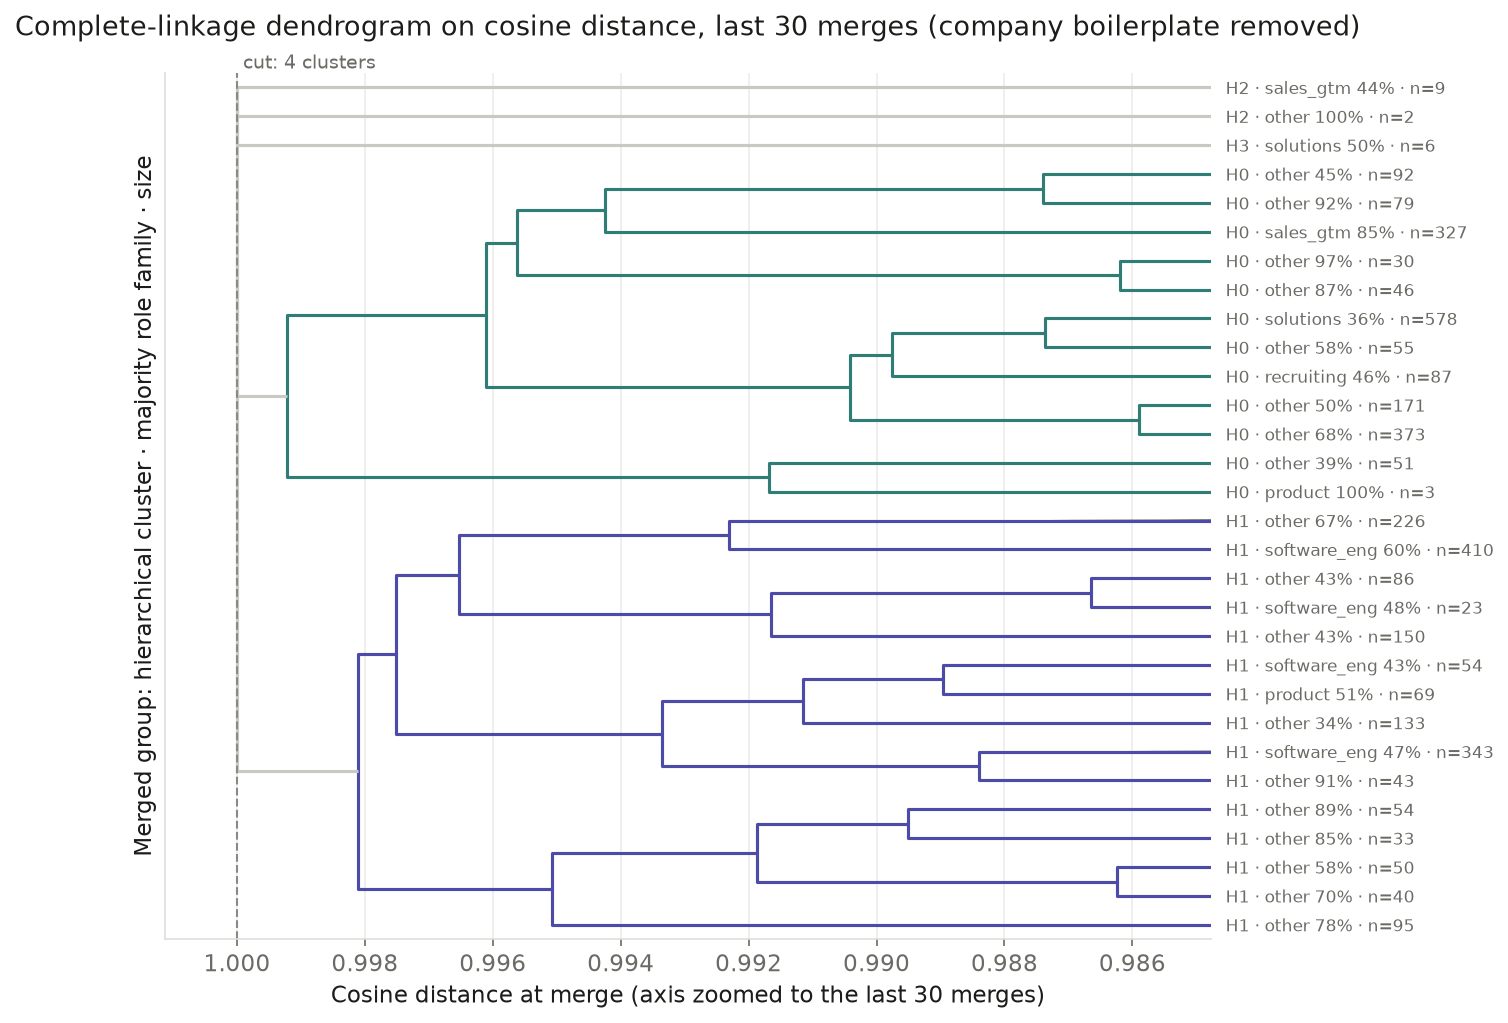

In [30]:
leaf_labels = tc.truncated_leaf_labels(hier["stripped"], P, roles, hier_labels["stripped"])
fig = plot_dendrogram(hier["stripped"], tc.cut_height(hier["stripped"], K["stripped"]), leaf_labels, P,
                      K["stripped"], LABEL["stripped"])
save(fig, "ats_hier_dendrogram_stripped")

## Insight
The tree really splits postings into two groups: H1 (1,809 postings) is the engineering group, H0 (1,892) mixes sales, solutions and forward_deployed postings, and the other two clusters are tiny (11 and 6 postings).

ARI between hierarchical and k-means clusters: 0.212


,K0,K2,K1,K3
H0,614,248,468,562
H1,481,1247,25,56
H2,11,0,0,0
H3,5,1,0,0


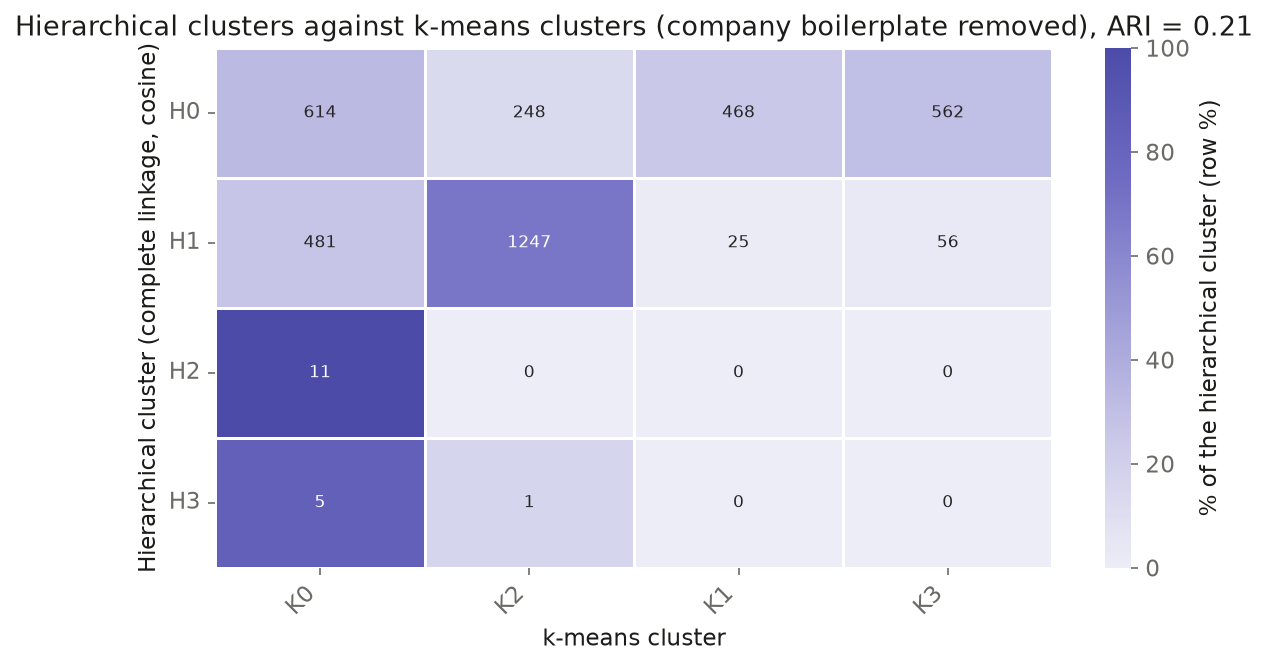

In [31]:
ct = tc.aligned_crosstab(hier_labels["stripped"], km["stripped"].labels_)
ari = adjusted_rand_score(hier_labels["stripped"], km["stripped"].labels_)
fig = plot_heatmap(ct, f"Hierarchical clusters against k-means clusters ({LABEL['stripped']}), ARI = {ari:.2f}",
                   "k-means cluster", "Hierarchical cluster (complete linkage, cosine)",
                   "% of the hierarchical cluster (row %)",
                   fmt="d", figsize=(9, 4.5),
                   color_by=ct.div(ct.sum(axis=1), axis=0) * 100)
save(fig, "ats_hier_vs_kmeans_stripped")

print(f"ARI between hierarchical and k-means clusters: {ari:.3f}")
ct

## Insight
Agreement is low (ARI = 0.21): hierarchical clustering mainly separates engineering (H1 holds 1,247 of 1,496 K2 postings) from everything else, while k-means also splits out sales, customer-technical and legal/finance groups.

In [32]:
print({k: round(val, 3) for k, val in tc.agreement(hier_labels["stripped"], postings).items()})
tc.role_crosstab(hier_labels["stripped"], roles, prefix="H").round(1)

{'nmi_company': 0.032, 'nmi_role_family': 0.121, 'ari_role_family': 0.068}


role_family,software_eng,sales_gtm,solutions,forward_deployed,product,applied_ai,research,data,recruiting,other
H2 (n=11),9.1,36.4,9.1,18.2,0.0,0.0,0.0,0.0,0.0,27.3
H3 (n=6),0.0,0.0,50.0,0.0,0.0,0.0,0.0,0.0,0.0,50.0
H0 (n=1892),5.5,24.7,12.4,5.1,3.6,2.6,0.1,0.6,2.5,42.9
H1 (n=1809),34.0,3.8,2.0,3.6,4.6,2.3,4.2,3.0,0.1,42.5


In [33]:
# hierarchical cluster x company
pd.crosstab(pd.Series(hier_labels["stripped"], name="hierarchical cluster"),
            postings.company_clean).rename(index=lambda c: f"H{c}")

company_clean,Airtable,Amplitude,Anthropic,Asana,Cohere,Databricks,Discord,Figma,Harvey,Linear,OpenAI,Palantir,Perplexity,Ramp,Scale AI,Sierra,Stripe,Vercel,Webflow
hierarchical cluster,,,,,,,,,,,,,,,,,,,
H0,8,27,234,51,57,493,10,84,128,13,300,38,39,75,75,129,73,44,14
H1,5,6,311,49,79,262,38,36,78,10,450,109,71,45,131,35,39,41,14
H2,0,0,5,0,0,3,0,0,0,0,0,3,0,0,0,0,0,0,0
H3,3,0,0,0,0,2,0,0,0,0,0,0,0,0,1,0,0,0,0


## 3. PCA
### 3a. Truncated SVD on the TF-IDF matrix

In [34]:
# TruncatedSVD rather than PCA: PCA needs a dense, mean-centred matrix, and densifying
# 3,718 x ~7,800 TF-IDF would also turn every implicit zero into a centred value.
# TruncatedSVD works on the sparse matrix directly; it does not mean-centre.
svd, coords = {}, {}
for v in X:
    svd[v], coords[v] = tc.fit_svd(X[v])
    r = svd[v].explained_variance_ratio_ * 100
    print(f"{v}: first 4 components {np.round(r[:4], 2).tolist()} %, "
          f"cumulative 10 / 50 / 100: {r[:10].sum():.1f} / {r[:50].sum():.1f} / {r.sum():.1f} %")

raw: first 4 components [1.11, 6.76, 5.22, 3.57] %, cumulative 10 / 50 / 100: 29.8 / 49.3 / 57.1 %


stripped: first 4 components [0.71, 2.39, 1.5, 1.19] %, cumulative 10 / 50 / 100: 11.1 / 27.2 / 37.0 %


In [35]:
FAMILIES = [f for f in roles.value_counts().index if f != "other"] + ["other"]

#### Raw descriptions

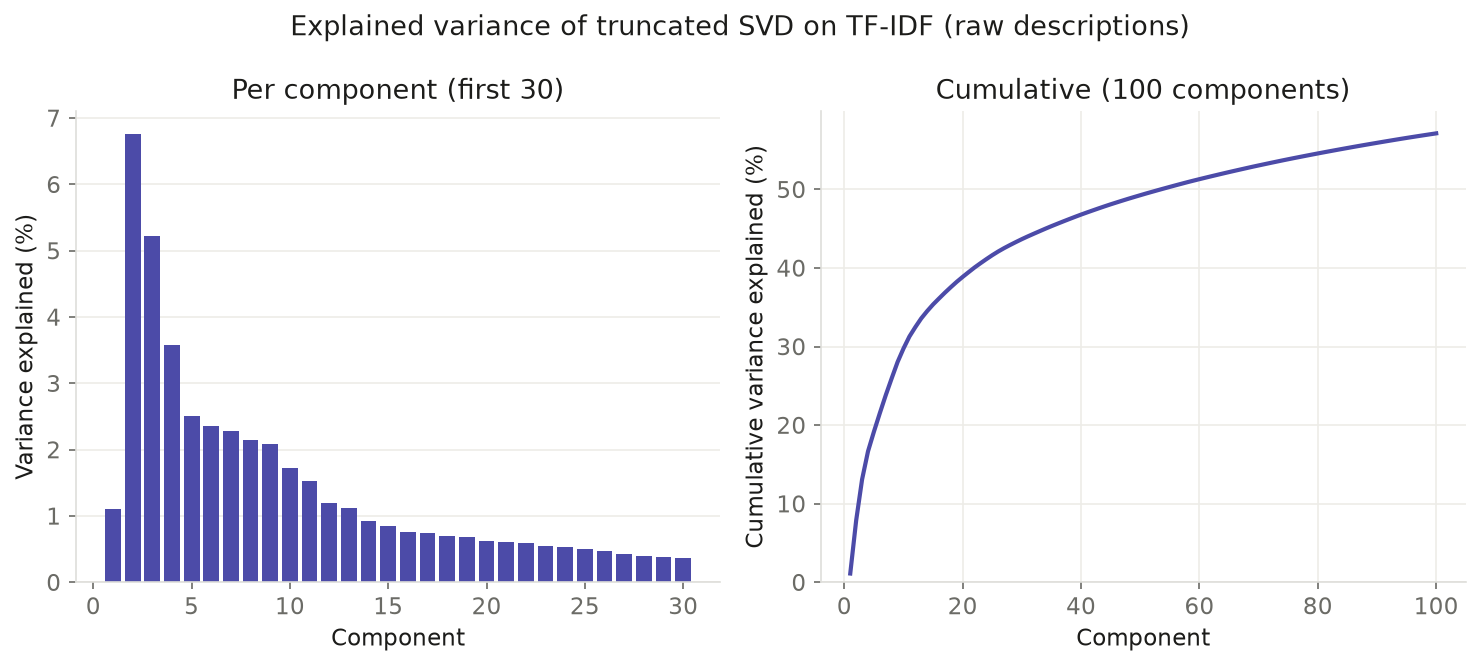

In [36]:
fig = plot_scree(svd["raw"], LABEL["raw"])
save(fig, "ats_svd_scree_raw")

## Insight
Variance is spread thinly: 10 components explain 30% and 100 explain 57%. Component 1 explains only 1.1% because truncated SVD does not centre the data.

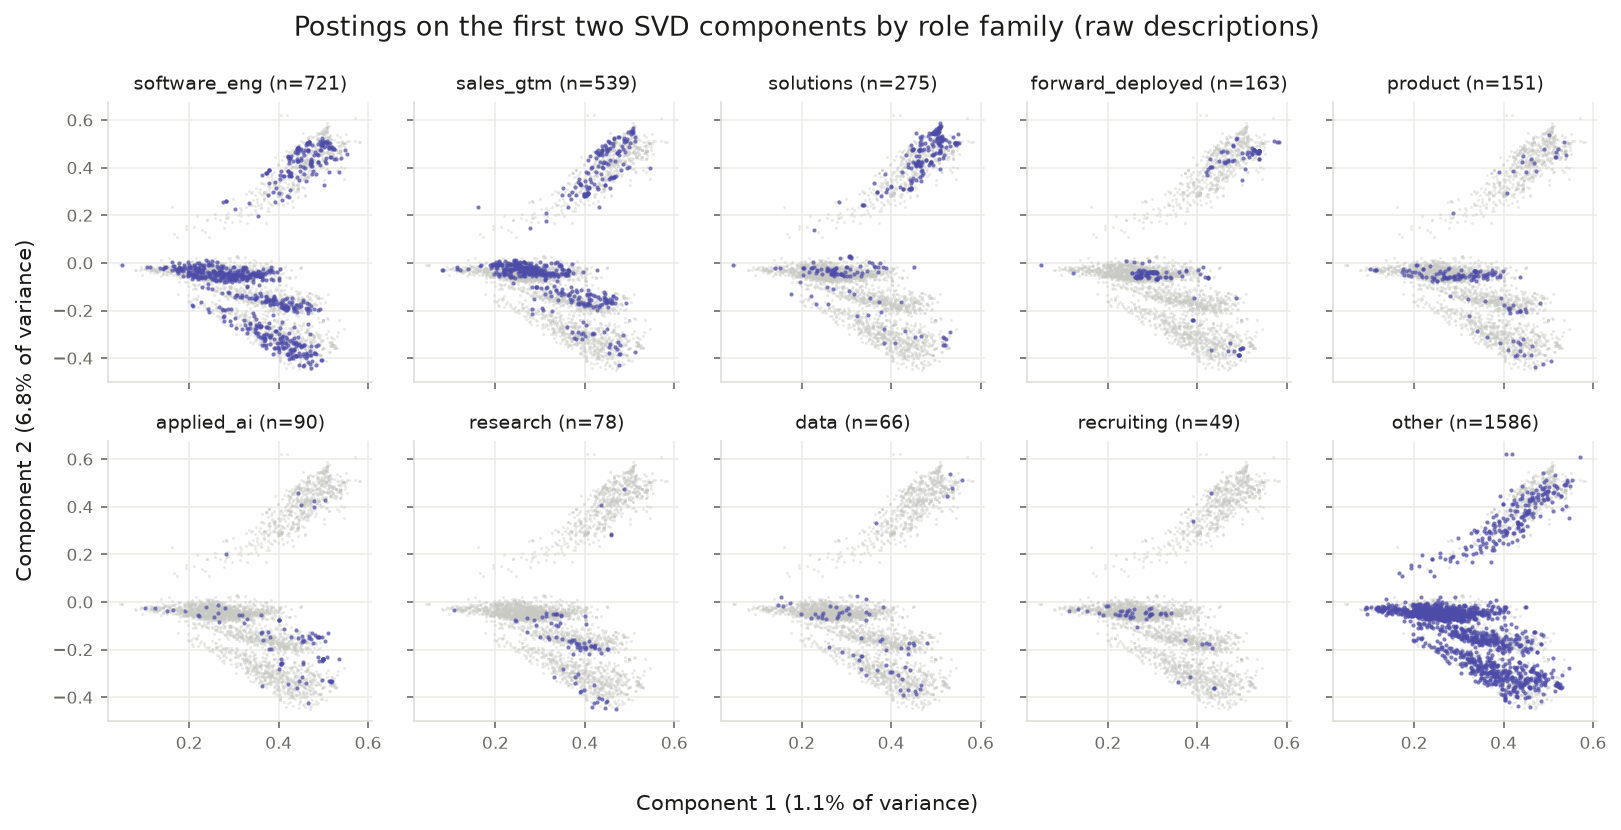

In [37]:
r = svd["raw"].explained_variance_ratio_ * 100
axis_labels = (f"Component 1 ({r[0]:.1f}% of variance)", f"Component 2 ({r[1]:.1f}% of variance)")
fig = plot_projection_facets(coords["raw"], roles, FAMILIES, ncols=5,
                             title=f"Postings on the first two SVD components by role family ({LABEL['raw']})",
                             axis_labels=axis_labels)
save(fig, "ats_svd_role_family_raw")

## Insight
Postings form three arms, one per large company (Databricks, OpenAI, Anthropic), and every role family appears on all three, so position shows the employer, not the job.

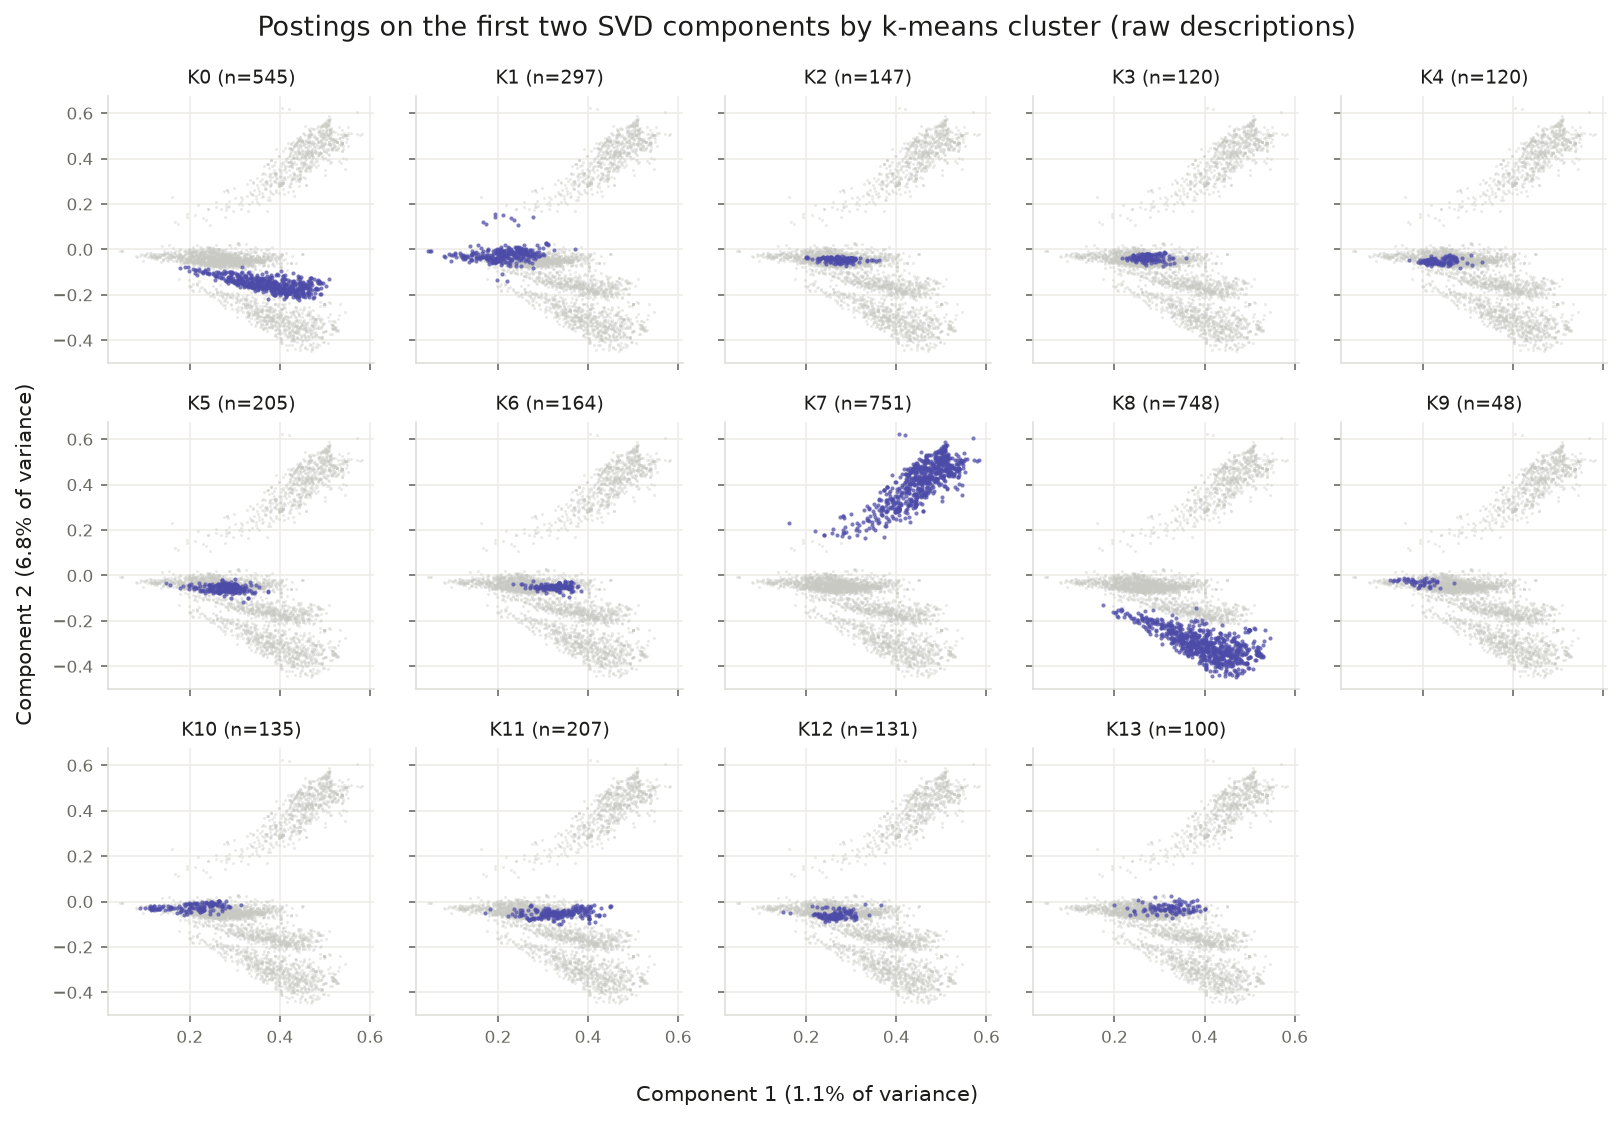

In [38]:
fig = plot_projection_facets(coords["raw"], km["raw"].labels_, list(range(K["raw"])), ncols=5,
                             title=f"Postings on the first two SVD components by k-means cluster ({LABEL['raw']})",
                             axis_labels=axis_labels, panel_name=lambda c: f"K{c}", figsize=(11, 7.5))
save(fig, "ats_svd_kmeans_raw")

## Insight
The three large company clusters, Databricks (K7), OpenAI (K8) and Anthropic (K0), each fill one arm, while the eleven smaller clusters overlap near zero.

In [39]:
tc.top_loadings(svd["raw"], terms["raw"])

,component,direction,terms
0,1,+,"databricks, openai, anthropic, technical, systems, customer, research, product, sales, range"
1,2,+,"databricks, platform, inclusive, range, lakebase, pay, analytics, commissionable, lakehouse, practices"
2,2,-,"openai, anthropic, research, policy, form, https, com, systems, hardware, chance"
3,3,+,"anthropic, research, single, range, beneficial, steerable, sales, minimum, science, visas"
4,3,-,"openai, databricks, form, https, employment, chance, hardware, artificial, humanity, fair"
5,4,+,"databricks, anthropic, openai, research, policy, form, hardware, safety, range, systems"
6,4,-,"palantir, sierra, harvey, figma, ramp, google, cohere, values, time, product"


#### Company boilerplate removed

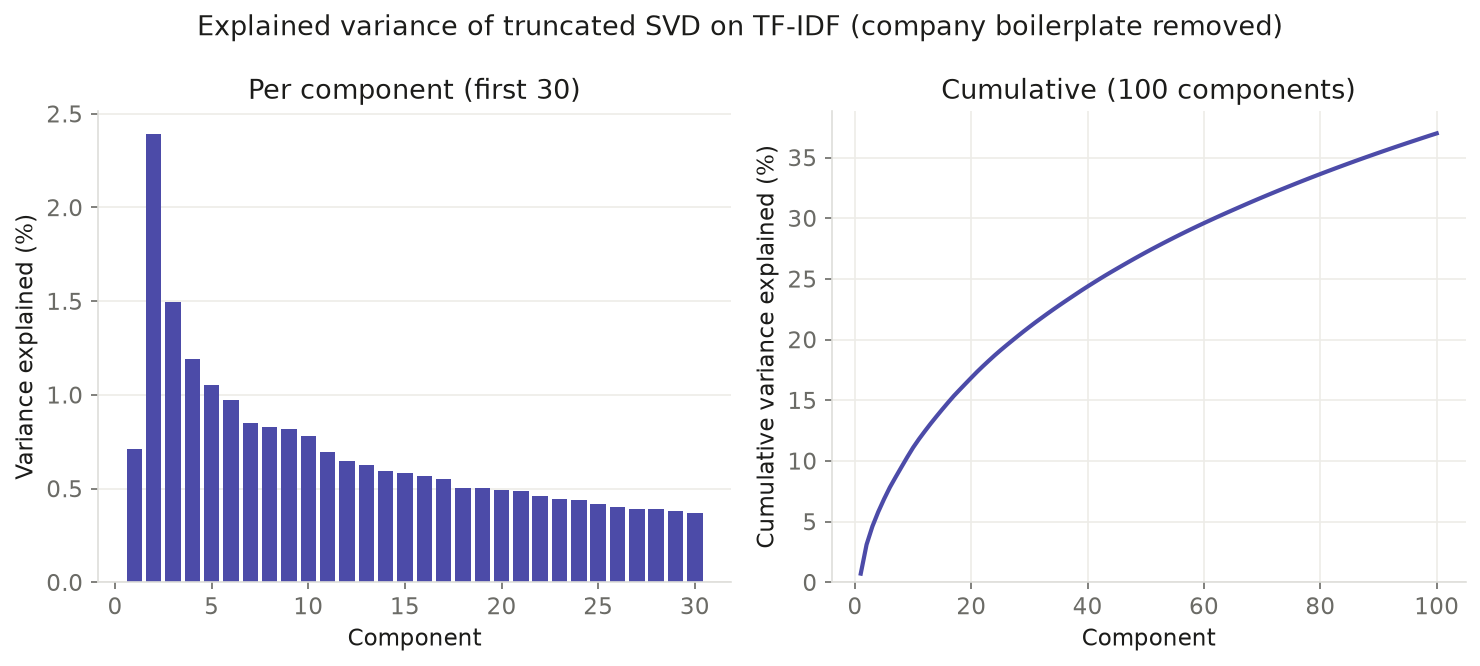

In [40]:
fig = plot_scree(svd["stripped"], LABEL["stripped"])
save(fig, "ats_svd_scree_stripped")

## Insight
Without boilerplate, variance is even more spread out: 10 components explain 11% and 100 explain 37%.

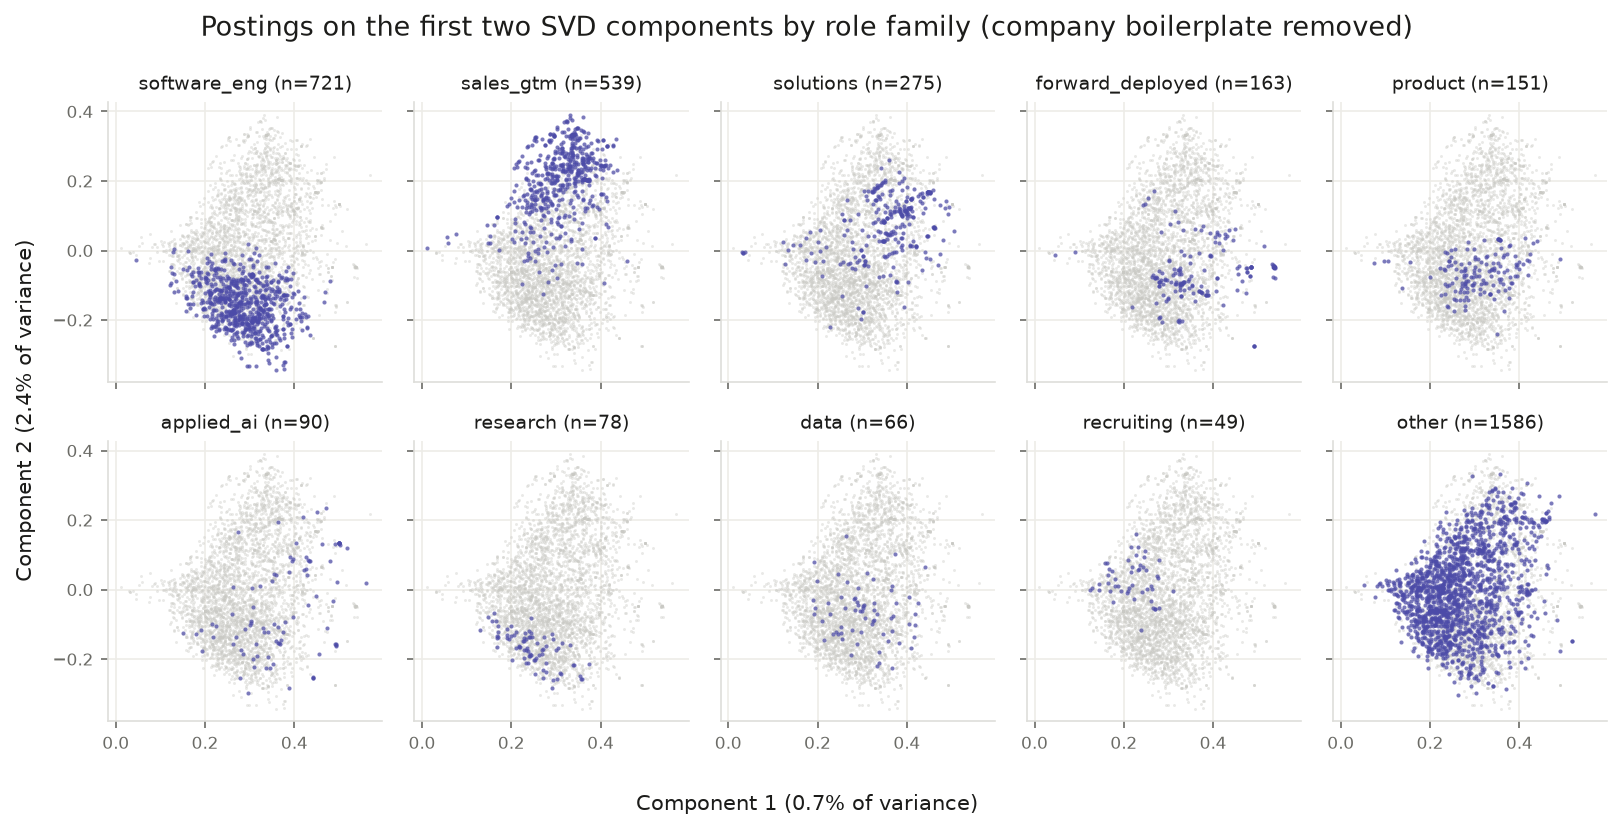

In [41]:
r = svd["stripped"].explained_variance_ratio_ * 100
axis_labels = (f"Component 1 ({r[0]:.1f}% of variance)", f"Component 2 ({r[1]:.1f}% of variance)")
fig = plot_projection_facets(coords["stripped"], roles, FAMILIES, ncols=5,
                             title=f"Postings on the first two SVD components by role family ({LABEL['stripped']})",
                             axis_labels=axis_labels)
save(fig, "ats_svd_role_family_stripped")

## Insight
Role families now separate: sales sits at the top, software engineering and research at the bottom, and solutions to the upper right, with forward_deployed in between.

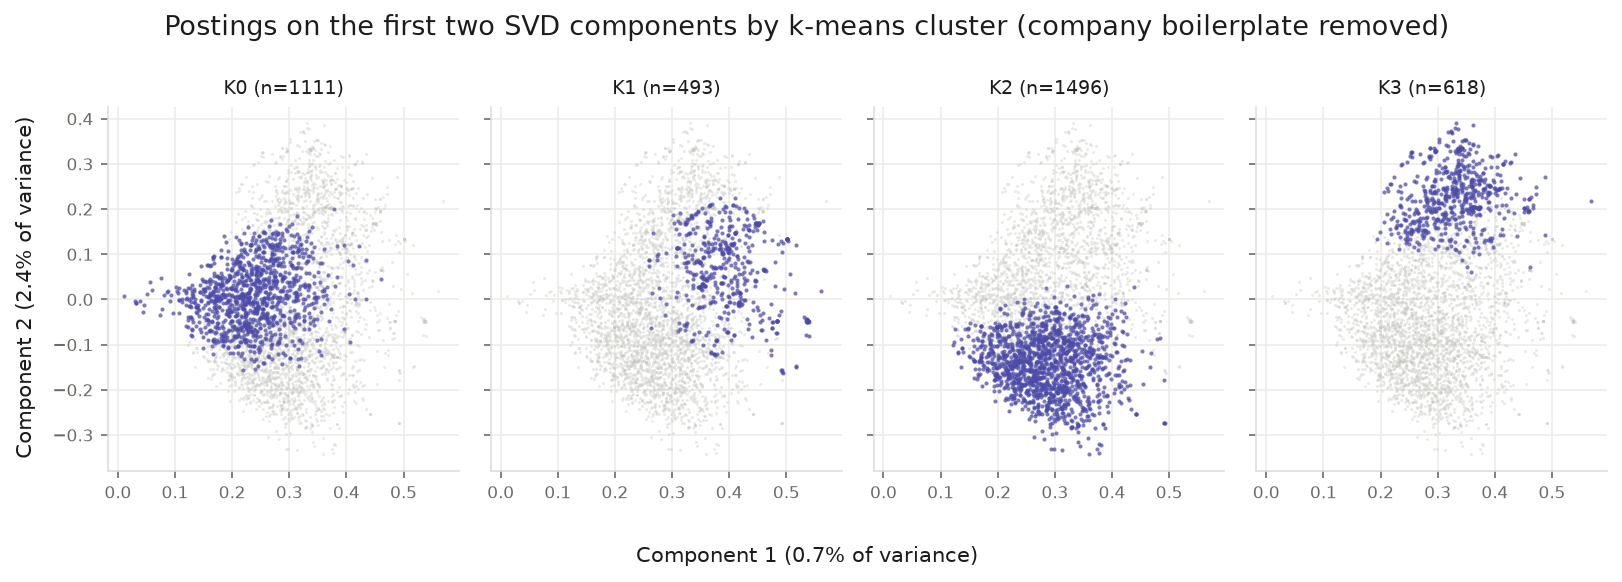

In [42]:
fig = plot_projection_facets(coords["stripped"], km["stripped"].labels_, list(range(K["stripped"])), ncols=4,
                             title=f"Postings on the first two SVD components by k-means cluster ({LABEL['stripped']})",
                             axis_labels=axis_labels, panel_name=lambda c: f"K{c}", figsize=(11, 3.8))
save(fig, "ats_svd_kmeans_stripped")

## Insight
The sales (K3) and engineering (K2) clusters are clearly apart, while the customer-technical (K1) and legal/finance (K0) clusters overlap with the others.

In [43]:
tc.top_loadings(svd["stripped"], terms["stripped"])

,component,direction,terms
0,1,+,"data, technical, ai, product, customer, sales, customers, engineering, systems, work"
1,2,+,"sales, account, customer, business, accounts, enterprise, revenue, strategic, value, executive"
2,2,-,"systems, infrastructure, security, research, production, engineering, design, model, reliability, engineers"
3,3,+,"data, customer, customers, technical, spark, solutions, architecture, big, science, platform"
4,3,-,"legal, marketing, partner, security, operations, accounting, programs, finance, commercial, market"
5,4,+,"security, infrastructure, cloud, compliance, data, operational, secure, controls, accounting, identity"
6,4,-,"product, research, agents, ai, agent, training, design, marketing, model, models"


### 3b. PCA on the Indeed sector panel

In [44]:
sector = pd.read_csv(sp.SECTOR_CSV)
panel, z, groups = sp.sector_matrix(sector, "total postings")
assert not z.isna().any().any()
print(f"matrix: {z.shape[0]} sectors x {z.shape[1]} months "
      f"({z.columns.min():%Y-%m} to {z.columns.max():%Y-%m}), monthly means, standardised per sector")
print(groups.value_counts().to_string())

# fit on months x sectors; see the sp module docstring for why this orientation
pca, profile, loadings = sp.fit_sector_pca(z)
ev = pca.explained_variance_ratio_ * 100
print(f"\nvariance explained, first 5 PCs: {np.round(ev[:5], 2).tolist()} %")
print(f"sectors loading positively on PC1: {(loadings.PC1 > 0).sum()} of {len(loadings)}")
loadings[["PC1", "PC2"]].join(groups).sort_values("PC1").round(3)

matrix: 47 sectors x 79 months (2020-02 to 2026-08), monthly means, standardised per sector
sector_group
control       44
ai_exposed     3

variance explained, first 5 PCs: [82.1, 12.3, 2.35, 1.18, 0.66] %
sectors loading positively on PC1: 47 of 47


,PC1,PC2,sector_group
display_name,,,
Physicians & Surgeons,0.473,0.829,control
Therapy,0.526,0.804,control
Civil Engineering,0.654,0.734,control
Dental,0.772,0.521,control
Driving,0.809,-0.281,control
Software Development,0.816,-0.538,ai_exposed
Aviation,0.822,0.481,control
Education & Instruction,0.841,0.510,control
Social Science,0.851,0.489,control


In [45]:
pc1 = profile.PC1
print(f"PC1 peak:   {pc1.idxmax():%Y-%m}  {pc1.max():.2f}")
print(f"PC1 trough: {pc1.idxmin():%Y-%m}  {pc1.min():.2f}")
print("\nPC1, Jan 2022 to Jun 2023:")
print(pc1.loc["2022-01":"2023-06"].round(2).to_string())

PC1 peak:   2022-03  11.06
PC1 trough: 2020-05  -14.27

PC1, Jan 2022 to Jun 2023:
month
2022-01-01     9.69
2022-02-01    10.55
2022-03-01    11.06
2022-04-01    10.96
2022-05-01    11.01
2022-06-01    10.56
2022-07-01     9.92
2022-08-01     9.28
2022-09-01     8.63
2022-10-01     8.21
2022-11-01     7.88
2022-12-01     7.04
2023-01-01     6.16
2023-02-01     5.19
2023-03-01     4.58
2023-04-01     4.48
2023-05-01     4.07
2023-06-01     3.30


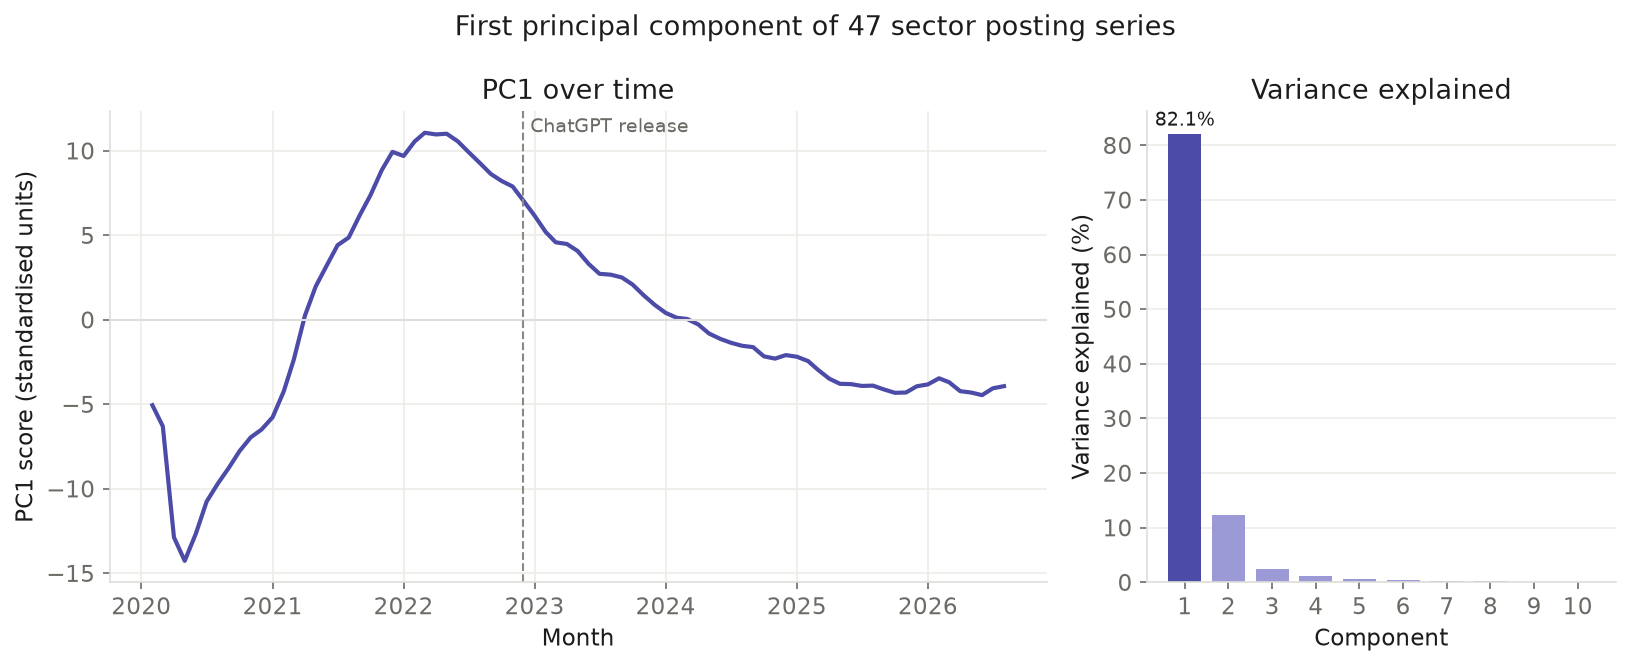

In [46]:
CHATGPT = pd.Timestamp("2022-11-30")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.5), gridspec_kw={"width_ratios": [2, 1]})
a1.plot(profile.index, profile.PC1, color=EXPOSED, lw=2)
a1.axhline(0, color="#DEDEDA", lw=1)
a1.axvline(CHATGPT, color="#8A8A84", ls="--", lw=1)
a1.text(CHATGPT + pd.Timedelta(days=20), a1.get_ylim()[1] * 0.9, "ChatGPT release",
        fontsize=9, color="#6B6B66")
a1.set_title("PC1 over time")
a1.set_xlabel("Month"); a1.set_ylabel("PC1 score (standardised units)")

n = 10
a2.bar(range(1, n + 1), ev[:n], color=[EXPOSED] + [SEQUENTIAL[2]] * (n - 1), width=0.75)
a2.text(1, ev[0] + 1.5, f"{ev[0]:.1f}%", ha="center", fontsize=9, color="#1C1C1A")
a2.set_title("Variance explained")
a2.set_xlabel("Component"); a2.set_ylabel("Variance explained (%)")
a2.set_xticks(range(1, n + 1))
a2.grid(axis="x", visible=False)
fig.suptitle(f"First principal component of {z.shape[0]} sector posting series")
fig.tight_layout()
save(fig, "indeed_sector_pc1")

## Insight
One shared pattern explains 82% of the movement in all 47 sectors. It peaks in March 2022 (11.06) and falls every month from June, reaching 7.88 in November. ChatGPT only came out on 30 November, so nearly all of this fall came before it, and much of the drop in postings hit the whole job market.

mean residual by year and group (standard deviations):


month,2020,2021,2022,2023,2024,2025,2026
sector_group,,,,,,,
ai_exposed,0.684,0.386,0.464,-0.625,-0.461,-0.274,-0.174
control,-0.079,-0.056,-0.040,0.058,0.052,0.042,0.027


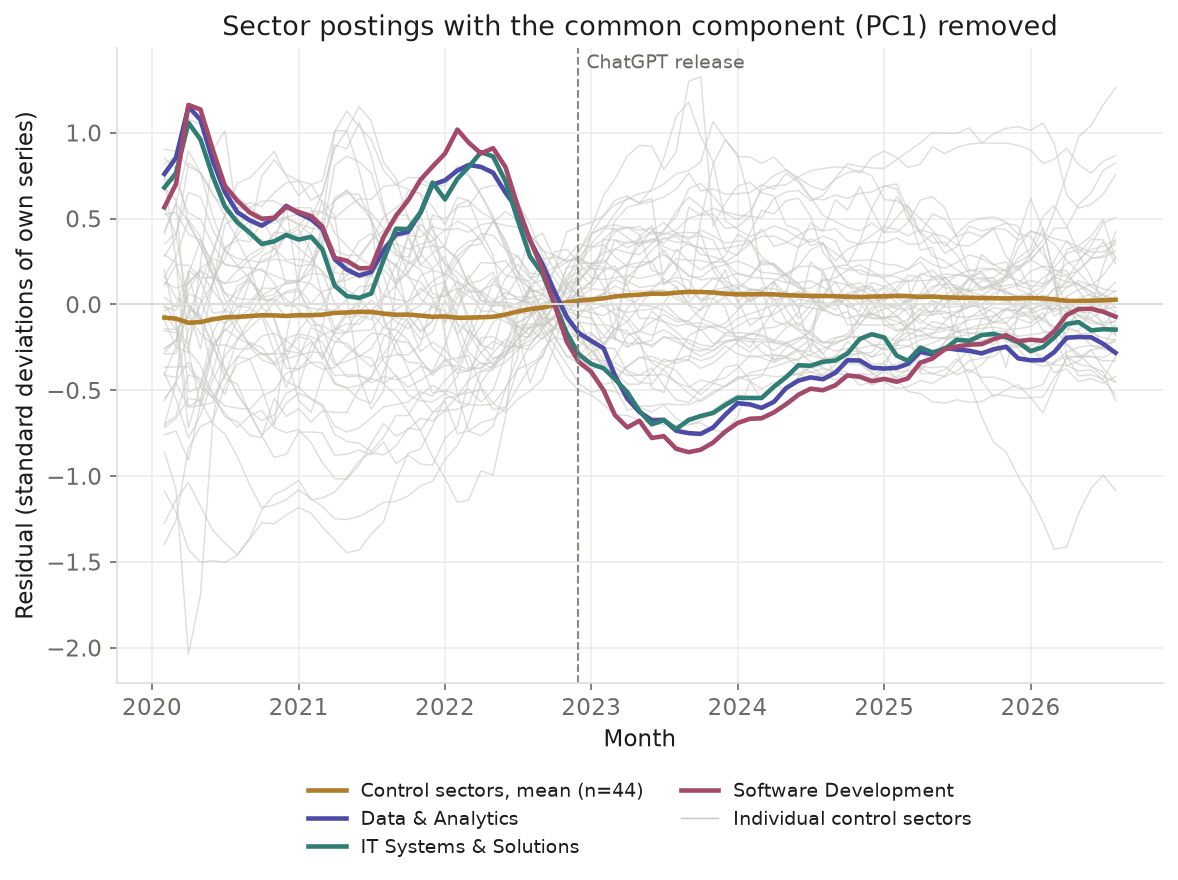

In [47]:
resid = sp.remove_pc1(z, pca, profile)
exposed = groups[groups == "ai_exposed"].index.tolist()
control = groups[groups == "control"].index

fig, ax = plt.subplots(figsize=(9, 5.5))
for s in control:
    ax.plot(resid.columns, resid.loc[s], color="#C9C9C4", lw=0.7, alpha=0.6)
ax.plot(resid.columns, resid.loc[control].mean(), color=CONTROL, lw=2.2,
        label=f"Control sectors, mean (n={len(control)})")
for s, c in zip(exposed, [PALETTE[0], PALETTE[2], PALETTE[3]]):
    ax.plot(resid.columns, resid.loc[s], color=c, lw=2.2, label=s)
ax.plot([], [], color="#C9C9C4", lw=0.7, label="Individual control sectors")
ax.axhline(0, color="#DEDEDA", lw=1)
ax.axvline(CHATGPT, color="#8A8A84", ls="--", lw=1)
ax.text(CHATGPT + pd.Timedelta(days=20), ax.get_ylim()[1] * 0.92, "ChatGPT release",
        fontsize=9, color="#6B6B66")
ax.set_title("Sector postings with the common component (PC1) removed")
ax.set_xlabel("Month"); ax.set_ylabel("Residual (standard deviations of own series)")
ax.legend(frameon=False, fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2)
save(fig, "indeed_sector_residuals_no_pc1")

print("mean residual by year and group (standard deviations):")
by_year = resid.T.groupby(resid.columns.year).mean().T.groupby(groups).mean()
by_year.round(3)

## Insight
Even with the shared pattern removed, the AI-exposed group's mean residual drops from 0.464 in 2022 to −0.625 in 2023 and only partly recovers (−0.461, −0.274, −0.174 through 2026), while the control group stays near zero. Only three sectors fell further than Software Development, and two of them are control sectors (IT Infrastructure, Operations & Support and Media & Communications), so it is unusual but not unique.

In [48]:
# shift in mean residual from before to after December 2022, in units of each
# sector's own pre-period residual SD; rank 1 = largest absolute shift of all 47
breaks = sp.break_table(resid, groups)
print("ai_exposed sectors:")
display(breaks.loc[exposed].round(3))
print("largest 10 shifts:")
breaks.head(10).round(3)

ai_exposed sectors:


,sector_group,mean_pre,mean_post,shift,shift_in_pre_sd,rank_abs_shift
display_name,,,,,,
Data & Analytics,ai_exposed,0.537,-0.406,-0.943,-3.429,5
IT Systems & Solutions,ai_exposed,0.469,-0.354,-0.823,-2.746,12
Software Development,ai_exposed,0.581,-0.439,-1.019,-3.269,8


largest 10 shifts:


,sector_group,mean_pre,mean_post,shift,shift_in_pre_sd,rank_abs_shift
display_name,,,,,,
Social Science,control,-0.526,0.397,0.923,5.663,1
Therapy,control,-0.903,0.682,1.585,4.075,2
Community & Social Service,control,-0.237,0.179,0.417,3.770,3
"IT Infrastructure, Operations & Support",control,0.480,-0.363,-0.843,-3.569,4
Data & Analytics,ai_exposed,0.537,-0.406,-0.943,-3.429,5
Physicians & Surgeons,control,-0.920,0.695,1.615,3.378,6
Media & Communications,control,0.453,-0.342,-0.795,-3.337,7
Software Development,ai_exposed,0.581,-0.439,-1.019,-3.269,8
Scientific Research & Development,control,0.424,-0.320,-0.744,-3.246,9


In [49]:
print("all 47 sectors, sorted by shift_in_pre_sd:")
print(breaks.sort_values("shift_in_pre_sd").round(3).to_string())

print("\ngroup means:")
display(breaks.groupby("sector_group")[["mean_pre", "mean_post", "shift", "shift_in_pre_sd"]]
        .mean().round(3))

all 47 sectors, sorted by shift_in_pre_sd:
                                        sector_group  mean_pre  mean_post  shift  shift_in_pre_sd  rank_abs_shift
display_name                                                                                                     
IT Infrastructure, Operations & Support      control     0.480     -0.363 -0.843           -3.569               4
Data & Analytics                          ai_exposed     0.537     -0.406 -0.943           -3.429               5
Media & Communications                       control     0.453     -0.342 -0.795           -3.337               7
Software Development                      ai_exposed     0.581     -0.439 -1.019           -3.269               8
Scientific Research & Development            control     0.424     -0.320 -0.744           -3.246               9
IT Systems & Solutions                    ai_exposed     0.469     -0.354 -0.823           -2.746              12
Marketing                                    

,mean_pre,mean_post,shift,shift_in_pre_sd
sector_group,,,,
ai_exposed,0.529,-0.400,-0.929,-3.148
control,-0.060,0.046,0.106,0.243


all 47 sectors, sorted by PC2 loading:
                                           PC1    PC2 sector_group
display_name                                                      
Physicians & Surgeons                    0.473  0.829      control
Therapy                                  0.526  0.804      control
Civil Engineering                        0.654  0.734      control
Dental                                   0.772  0.521      control
Education & Instruction                  0.841  0.510      control
Social Science                           0.851  0.489      control
Aviation                                 0.822  0.481      control
Personal Care & Home Health              0.905  0.356      control
Electrical Engineering                   0.910  0.329      control
Mechanical Engineering                   0.898  0.304      control
Community & Social Service               0.961  0.229      control
Childcare                                0.937  0.218      control
Legal                  

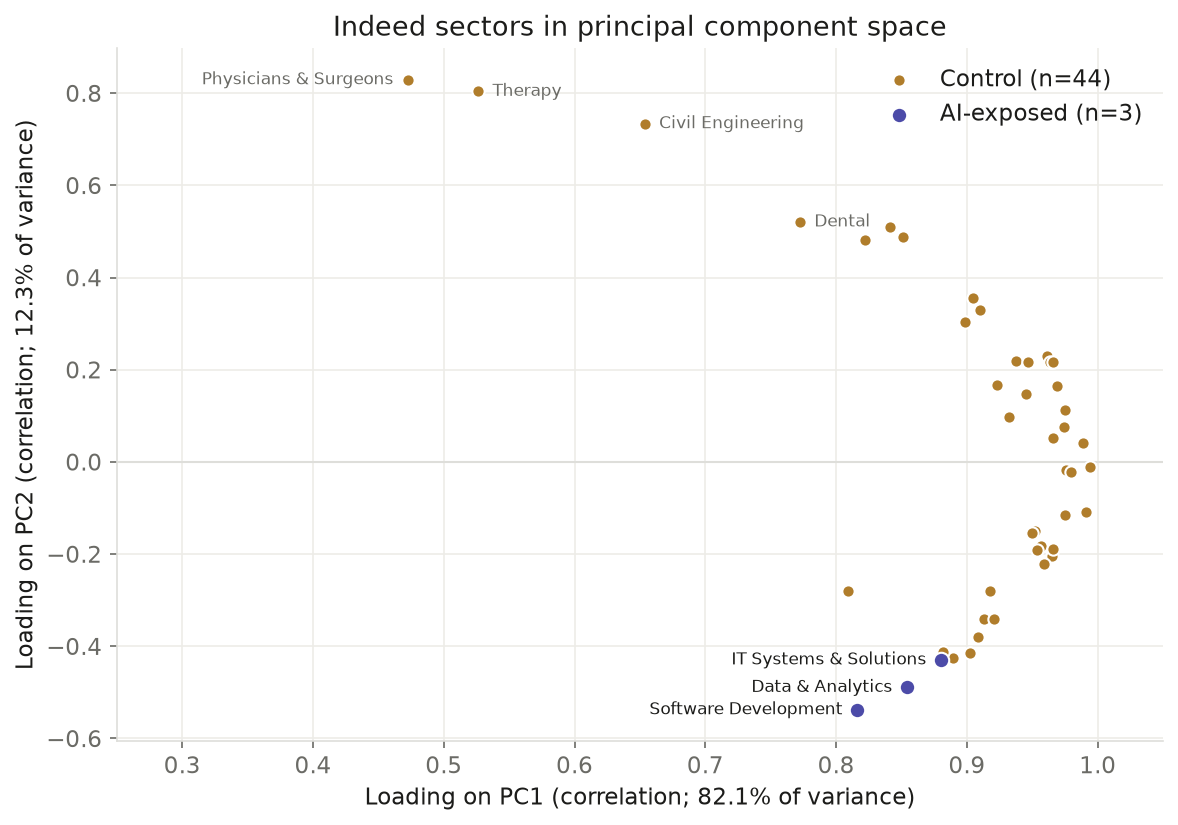

In [50]:
fig, ax = plt.subplots(figsize=(9, 6))
for g, c, lab in [("control", CONTROL, "Control"), ("ai_exposed", EXPOSED, "AI-exposed")]:
    m = groups == g
    ax.scatter(loadings.PC1[m], loadings.PC2[m], s=55 if g == "ai_exposed" else 35,
               color=c, edgecolor="white", lw=1, label=f"{lab} (n={m.sum()})", zorder=3)
# label the AI-exposed sectors and the four controls furthest out on PC2; labels go
# left of points that sit in the dense right-hand edge or beside another labelled point
extremes = loadings.PC2.drop(exposed).abs().nlargest(4).index.tolist()
left = set(exposed) | {loadings.PC1[extremes].idxmin()}
for s in exposed + extremes:
    ax.annotate(s, (loadings.PC1[s], loadings.PC2[s]), xytext=(-7 if s in left else 7, 0),
                textcoords="offset points", fontsize=8, va="center",
                ha="right" if s in left else "left",
                color="#1C1C1A" if s in exposed else "#6B6B66")
ax.axhline(0, color="#DEDEDA", lw=1)
ax.set_xlim(0.25, 1.05)
ax.set_title("Indeed sectors in principal component space")
ax.set_xlabel(f"Loading on PC1 (correlation; {ev[0]:.1f}% of variance)")
ax.set_ylabel(f"Loading on PC2 (correlation; {ev[1]:.1f}% of variance)")
ax.legend(frameon=False, loc="upper right")
save(fig, "indeed_sector_pc_space")

print("all 47 sectors, sorted by PC2 loading:")
print(loadings[["PC1", "PC2"]].join(groups).sort_values("PC2", ascending=False).round(3).to_string())

## Insight
All sectors load positively on PC1. On PC2, the top is mostly healthcare (Physicians & Surgeons, Therapy and Dental, with Civil Engineering third), while Software Development and Data & Analytics are the two lowest of all 47 and IT Systems & Solutions is close behind, next to Marketing, Media and IT Infrastructure.

## Outputs

In [51]:
clusters = postings[["jobId", "company_clean", "title", "role_family"]].copy()
for v in X:
    clusters[f"kmeans_{v}"] = km[v].labels_
    clusters[f"hier_{v}"] = hier_labels[v]
clusters.to_csv(tc.CLUSTERS_CSV, index=False)
print(f"wrote {tc.CLUSTERS_CSV.relative_to(tc.ROOT)}: {clusters.shape}")
clusters.head()

wrote data/processed/ats_clusters.csv: (3718, 8)


,jobId,company_clean,title,role_family,kmeans_raw,hier_raw,kmeans_stripped,hier_stripped
0,ac978161-6f46-4f6b-ad9e-a258e642751c,Palantir,Administrative Business Partner,other,2,0,0,0
1,10dfc8bc-99ad-4ca2-ab76-853cb90a92c2,Palantir,Backend Software Engineer - Application Development,software_eng,2,0,2,1
2,1345438c-ebfc-4fa5-b545-30c1414f317c,Palantir,Backend Software Engineer - Defense,software_eng,2,0,2,1
3,6fe5515f-f677-4d98-8ac2-1775a425f5e7,Palantir,Backend Software Engineer - Infrastructure,software_eng,2,0,2,1
4,fb2d3222-dbd8-4e03-8d39-47b820e9509c,Palantir,"Backend Software Engineer - Infrastructure, Foundations",software_eng,2,0,2,1


In [52]:
def block(title, df):
    return [title, *[f"  {line}" for line in df.to_string().splitlines()]]

report.append(f"  TF-IDF parameters: {tc.TFIDF_PARAMS}")
report.append(f"  boilerplate rule (stripped variant): sentence in >= {tc.BOILERPLATE_SHARE:.0%} "
              f"of a company's postings and >= {tc.BOILERPLATE_MIN} of them; company names removed")
for v in X:
    labels, hl = km[v].labels_, hier_labels[v]
    landing_pct, landing_n = tc.family_landing(labels, roles)
    report += ["", "=" * 70, f"TEXT VARIANT: {v} ({LABEL[v]})", "=" * 70,
               f"chosen k = {K[v]}: {K_REASON[v]}",
               f"silhouette of final k-means fit (seed {tc.RANDOM_STATE}): "
               f"{silhouette_score(X[v], labels):.4f}"]
    report += block("k sweep (silhouette = mean of 5 seeds; stability = mean pairwise ARI):",
                    sweep[v].round(4))
    report += block(f"k-means compared at k = {KS_COMPARE} (silhouette of the seed-{tc.RANDOM_STATE} fit):",
                    compare[v].round(3))
    report.append(f"k-means cluster sizes (chosen k): {np.bincount(labels).tolist()}")
    report += block("k-means cluster x role_family (row %):", tc.role_crosstab(labels, roles).round(1))
    report += block("role_family x k-means cluster (counts):", landing_n)
    report.append(f"k-means agreement: { {k: round(x, 3) for k, x in tc.agreement(labels, postings).items()} }")
    report += ["Hierarchical: cosine distance, complete linkage",
               f"  cophenetic correlation = {coph[v]:.4f}",
               f"  cluster sizes (cut at k = {K[v]}): {np.bincount(hl).tolist()}",
               f"  for comparison, average linkage at k = {K[v]}: sizes {avg_check[v][0]}, "
               f"cophenetic {avg_check[v][1]:.4f}",
               f"  hierarchical vs k-means ARI = {adjusted_rand_score(hl, labels):.4f}",
               f"  agreement: { {k: round(x, 3) for k, x in tc.agreement(hl, postings).items()} }"]
    report += block("k suggested by the tree (merge gap, cosine silhouette of each cut):", scan[v].round(4))
    report += block("k suggested, hierarchical vs k-means:", k_suggest[[v]])
    report += block("hierarchical cluster x role_family (row %):", tc.role_crosstab(hl, roles, prefix="H").round(1))
    report += block("hierarchical x k-means (counts):", tc.aligned_crosstab(hl, labels))
    r = svd[v].explained_variance_ratio_ * 100
    report += [f"TruncatedSVD explained variance (%), components 1-{len(r)} "
               f"(cumulative {r.sum():.2f}%):",
               *[f"  {i + 1:>3}-{min(i + 10, len(r)):>3}: " + "  ".join(f"{x:.3f}" for x in r[i:i + 10])
                 for i in range(0, len(r), 10)]]

report += ["", "=" * 70, "INDEED SECTOR PCA (total postings, monthly means, standardised per sector)",
           "=" * 70, f"matrix: {z.shape[0]} sectors x {z.shape[1]} months",
           f"sectors loading positively on PC1: {(loadings.PC1 > 0).sum()} of {len(loadings)}",
           "explained variance (%) per component:",
           *[f"  PC{i + 1:>2}: {x:6.3f}   cumulative {c:6.2f}"
             for i, (x, c) in enumerate(zip(ev, ev.cumsum()))]]
report += block("residual shift after removing PC1 (Dec 2022 onward vs before), ai_exposed:",
                breaks.loc[exposed].round(3))
report += block("largest 10 residual shifts:", breaks.head(10).round(3))

tc.REPORT_PATH.parent.mkdir(exist_ok=True)
tc.REPORT_PATH.write_text("\n".join(report) + "\n")
print(f"wrote {tc.REPORT_PATH.relative_to(tc.ROOT)} ({len(report)} lines)")

wrote results/clustering_report.txt (330 lines)
